# Synthetic data demo

This notebook shows how mm-healthfusion stores and loads multimodal training data, using fictional
records written by `src.preprocessing.generate_synthetic`. It covers both pathways, deterioration
and hospitalisation, and follows the path from parquet split files to PyTorch samples and collated
training batches. It ends with a short run of the static MoE model on the deterioration files,
its evaluation and its interpretation.

The files use the **average-record** layout, the input of the static fusion models (concatenation,
M3Care and the static MoE model). Each ECG, CXR or notes modality holds one averaged embedding, and
vital-sign and lab measurements are reduced to summary statistics. No observation times are
stored.

**The data is synthetic.** Every record, identifier and outcome is artificial and has no clinical
interpretation. The generator does not try to reproduce real clinical distributions. It only
builds learnable relationships between a few hidden factors and the outcome.

Run the cells from top to bottom. No MIMIC access or model download is needed. Training uses a GPU
if one is present but does not need one. The
[synthetic data guide](../docs/examples/synthetic.md) lists the generator options and shows how to
train the existing models on these files.

## 1. Setup and data generation

The first cell takes the repository root as the folder above this notebook and adds it to the
import path, so no paths need editing.

In [1]:
import json
import subprocess
import sys
import warnings
from contextlib import redirect_stderr, redirect_stdout
from io import BytesIO, StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import Patch
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image as PILImage

# The repository plotting modules switch matplotlib to the file-only Agg backend.
# Keep the notebook backend so figures can be shown again after them.
NOTEBOOK_BACKEND = plt.get_backend()
warnings.filterwarnings("ignore", message="IProgress not found")

# The repository root is the folder above this notebook
REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.collate import batch_modality_availability, get_collate_fn
from src.data.datasets import (
    SPLIT_NAMES,
    TABULAR_MODALITIES,
    DeteriorationDataset,
    HospitalisationDataset,
    modality_columns,
    modality_prefix,
    resolve_split_path,
)
from src.preprocessing.generate_synthetic import (
    DEFAULT_OUTPUT_DIR,
    DEMOGRAPHICS_FILENAME,
    MANIFEST_FILENAME,
    OUTCOMES,
    TASKS,
    generate,
)
from src.data.splits import get_dataloaders
from src.evaluation.eval_utils import read_predictions
from src.evaluation.fairness import compute_fairness_for_run
from src.explanation.explain import explain_checkpoint
from src.train import DEFAULT_LOG_DIR, resolve_run_dir

plt.switch_backend(NOTEBOOK_BACKEND)

np.set_printoptions(precision=3, suppress=True, linewidth=110)
# Colours and axis style shared with the report notebooks
PURPLE, TEAL, OCHRE, SLATE, RED = "#6D2E8E", "#0E7C84", "#BE7C1C", "#3B4C61", "#B0413E"
INK, MUTED, GRID = "#404040", "#898781", "#E3E3E3"
TASK_COLOURS = {"deterioration": PURPLE, "hospitalisation": TEAL}
MODALITY_COLOURS = {
    "tabular": PURPLE, "static": PURPLE,
    "ts_prev": "#E2BC7E", "ts_curr": OCHRE,
    "ecg": TEAL, "ecg_curr": TEAL,
    "cxr": RED, "cxr_prev": "#DBA5A3", "cxr_curr": RED,
    "notes_prev": "#999999",
}
plt.rcParams.update(
    {
        "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": INK,
        "xtick.color": INK, "ytick.color": INK,
        "axes.spines.top": False, "axes.spines.right": False,
        "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False,
    }
)
# Render inline figures at twice the resolution, shown at the same size
set_matplotlib_formats("retina")

The generator writes to `../outputs/synthetic` by default, the folder beside the repository that
also holds the real prepared datasets. The next cell creates the files with the default settings
if they are missing: 1,000 fictional records per pathway and seed 42. Running the generator again
replaces them.

In [2]:
OUTPUT_DIR = DEFAULT_OUTPUT_DIR


def shown(path: Path) -> str:
    """Show a path relative to the repository's parent folder when possible."""
    try:
        return f"../{path.relative_to(REPO_ROOT.parent)}"
    except ValueError:
        return str(path)


missing_tasks = [task for task in TASKS if not (OUTPUT_DIR / task / MANIFEST_FILENAME).exists()]
if missing_tasks:
    print(f"Generating {', '.join(missing_tasks)} in {shown(OUTPUT_DIR)}")
    generate(missing_tasks, output_dir=OUTPUT_DIR)
else:
    print(f"Using the existing synthetic data in {shown(OUTPUT_DIR)}")

manifests = {
    task: json.loads((OUTPUT_DIR / task / MANIFEST_FILENAME).read_text(encoding="utf-8"))
    for task in TASKS
}
print(manifests["deterioration"]["notice"])
for task, manifest in manifests.items():
    print(f"{task}: {manifest['parameters']['n_samples']} records -> {manifest['split_counts']}")

Using the existing synthetic data in ../outputs/synthetic

Synthetic data. Every record, identifier and outcome is artificial and has no clinical interpretation. No real patient information was used.

deterioration: 1000 records -> {'train': 800, 'val': 100, 'test': 100}

hospitalisation: 1000 records -> {'train': 800, 'val': 100, 'test': 100}

Each pathway holds 1,000 records split 80/10/10, giving 800 training, 100 validation and 100 test
records. The split is stratified by outcome with seed 42, so every split contains both classes,
and no fictional patient appears in more than one split. Deterioration has one ED encounter per
patient and hospitalisation has one current admission per patient.

Each pathway folder also holds `synthetic_manifest.json`, which records the generator settings,
the counts and the mechanisms behind the synthetic signal and missingness.

## 2. Dataset overview

The manifests summarise the split sizes and the outcome balance. Deterioration predicts
`deterioration_mechanical_ventilation` and hospitalisation predicts `hospitalisation_ext_stay_7`.

In [3]:
split_summary = pd.DataFrame(
    {
        task: {
            "outcome": manifest["outcome"],
            **{f"{split} records": count for split, count in manifest["split_counts"].items()},
            **{
                f"{split} positive (%)": round(100 * rate, 1)
                for split, rate in manifest["outcome_prevalence"].items()
            },
        }
        for task, manifest in manifests.items()
    }
)
display(split_summary)

,deterioration,hospitalisation
outcome,deterioration_mechanical_ventilation,hospitalisation_ext_stay_7
train records,800,800
val records,100,100
test records,100,100
train positive (%),28.1,31.5
val positive (%),28.0,32.0
test positive (%),28.0,31.0


The table below lists every modality, the parquet columns that store it, its feature width and the
share of records that contain it. Tabular data is always present. The other modalities are
optional, as in the real data. Deterioration has no separate time-series modality. Its vital-sign
and lab summaries are part of the `tabular` vector, which is why that vector is wider than the
hospitalisation `static` one.

In [4]:
modality_summary = pd.DataFrame(
    [
        {
            "pathway": task,
            "modality": modality,
            "parquet columns": ", ".join(modality_columns(modality)),
            "feature width": manifest["feature_dims"][modality],
            "records with modality (%)": round(100 * manifest["modality_availability"][modality], 1),
        }
        for task, manifest in manifests.items()
        for modality in manifest["modalities"]
    ]
)
display(modality_summary)

for task, manifest in manifests.items():
    print(
        f"{task}: {100 * manifest['tabular_feature_missing_rate']:.1f}% of tabular values and "
        f"{100 * manifest['summary_statistic_missing_rate']:.1f}% of measurement summaries are "
        "missing"
    )

,pathway,modality,parquet columns,feature width,records with modality (%)
0,deterioration,tabular,"tab_feats, tab_missing",88,100.0
1,deterioration,ecg,"ecg_feats, ecg_time, ecg_missing",768,65.8
2,deterioration,cxr,"cxr_feats, cxr_time, cxr_missing",1024,52.9
3,hospitalisation,static,"tab_feats, tab_missing",16,100.0
4,hospitalisation,ts_prev,"ts_prev_feats, ts_prev_time, ts_prev_missing",72,55.2
5,hospitalisation,ts_curr,"ts_curr_feats, ts_curr_time, ts_curr_missing",72,94.6
6,hospitalisation,ecg_curr,"ecg_curr_feats, ecg_curr_time, ecg_curr_missing",768,66.6
7,hospitalisation,cxr_prev,"cxr_prev_feats, cxr_prev_time, cxr_prev_missing",1024,29.3
8,hospitalisation,cxr_curr,"cxr_curr_feats, cxr_curr_time, cxr_curr_missing",1024,51.7
9,hospitalisation,notes_prev,"notes_prev_feats, notes_prev_time, notes_prev_...",768,48.6


deterioration: 21.2% of tabular values and 18.9% of measurement summaries are missing

hospitalisation: 30.9% of tabular values and 18.9% of measurement summaries are missing

The split files are ordinary parquet files, so pandas reads them directly. Tabular features are
flat lists. ECG, CXR, notes and the hospitalisation time series
are lists of lists, which in the average-record layout hold one row when the modality is present
and none when it is absent. The `*_time` columns are kept for the shared schema but are always
empty.

In [5]:
frames = {
    task: {
        split: pd.read_parquet(resolve_split_path(OUTPUT_DIR / task, split))
        for split in SPLIT_NAMES
    }
    for task in TASKS
}

Each file has one row per fictional patient or encounter. Array cells are long, so printing a frame
directly floods the screen. The view below replaces each array cell with its shape.

In [6]:
def cell_shape(value: object) -> object:
    """Describe an array cell by its shape and leave scalars unchanged."""
    if isinstance(value, np.ndarray):
        if value.dtype == object:
            return f"{len(value)} x {len(value[0])}" if len(value) else "empty"
        return f"[{len(value)}]"
    return value


train = frames["deterioration"]["train"]
display(train.head(4).map(cell_shape).T)

,0,1,2,3
ed_hadm_id,2000001,2000004,2000005,2000006
ed_stay_id,3000001,3000004,3000005,3000006
subject_id,1000001,1000004,1000005,1000006
deterioration_mechanical_ventilation,0,1,0,0
tab_feats,[88],[88],[88],[88]
tab_missing,[88],[88],[88],[88]
ecg_feats,1 x 768,empty,1 x 768,1 x 768
ecg_time,[0],[0],[0],[0]
ecg_missing,0,1,0,0
cxr_feats,empty,empty,1 x 1024,empty


## 3. Patient-level examples

A short summary per record shows its identifiers, its label and, for each modality, whether it is
present, the shape of its features and a few example values.

In [7]:
def describe_record(row: pd.Series, modalities: list[str], outcome: str) -> pd.DataFrame:
    """Summarise one record's modalities without printing whole arrays."""
    print(
        f"subject_id {row['subject_id']}, ed_stay_id {row['ed_stay_id']}, "
        f"ed_hadm_id {row['ed_hadm_id']}, {outcome} = {row[outcome]}"
    )
    rows = []
    for modality in modalities:
        prefix = modality_prefix(modality)
        if modality in TABULAR_MODALITIES:
            feats, missing = row[f"{prefix}_feats"], row[f"{prefix}_missing"]
            rows.append(
                {
                    "modality": modality,
                    "present": True,
                    "shape": f"[{len(feats)}]",
                    "missing values": int(missing.sum()),
                    "first values": np.round(feats[:4], 3).tolist(),
                }
            )
            continue
        feats = row[f"{prefix}_feats"]
        present = len(feats) > 0
        rows.append(
            {
                "modality": modality,
                "present": present,
                "shape": f"{len(feats)} x {len(feats[0])}" if present else "empty",
                "missing values": (
                    int(np.stack(row[f"{prefix}_missing"]).sum())
                    if present and modality.startswith("ts")
                    else "-"
                ),
                "first values": np.round(feats[0][:4], 3).tolist() if present else [],
            }
        )
    return pd.DataFrame(rows)


det = frames["deterioration"]["train"]
hosp = frames["hospitalisation"]["train"]
det_modalities = manifests["deterioration"]["modalities"]
hosp_modalities = manifests["hospitalisation"]["modalities"]


def has(frame: pd.DataFrame, modality: str) -> pd.Series:
    return frame[f"{modality}_feats"].map(len) > 0


complete = det[has(det, "ecg") & has(det, "cxr")]
display(describe_record(complete.iloc[0], det_modalities, OUTCOMES["deterioration"]))

subject_id 1000005, ed_stay_id 3000005, ed_hadm_id 2000005, deterioration_mechanical_ventilation = 0

,modality,present,shape,missing values,first values
0,tabular,True,[88],18,"[0.5849999785423279, 0.7689999938011169, 0.351..."
1,ecg,True,1 x 768,-,"[0.4490000009536743, -0.8799999952316284, 2.29..."
2,cxr,True,1 x 1024,-,"[0.8629999756813049, -1.5290000438690186, 0.23..."


**Missing ECG or CXR.** The modality-level flag is 1 and the feature array is empty.

In [8]:
no_imaging = det[~has(det, "ecg") | ~has(det, "cxr")]
display(describe_record(no_imaging.iloc[0], det_modalities, OUTCOMES["deterioration"]))

subject_id 1000001, ed_stay_id 3000001, ed_hadm_id 2000001, deterioration_mechanical_ventilation = 0

,modality,present,shape,missing values,first values
0,tabular,True,[88],6,"[0.30000001192092896, 0.6850000023841858, 0.53..."
1,ecg,True,1 x 768,-,"[-0.5299999713897705, 0.13500000536441803, -0...."
2,cxr,False,empty,-,[]


**Missing tabular measurements.** The tabular vector keeps its full width. Missing entries hold
the placeholder 0.0 and are marked 1 in `tab_missing`.

In [9]:
sparse_tabular = det[det["tab_missing"].map(sum) >= 4]
display(describe_record(sparse_tabular.iloc[0], det_modalities, OUTCOMES["deterioration"]))

subject_id 1000001, ed_stay_id 3000001, ed_hadm_id 2000001, deterioration_mechanical_ventilation = 0

,modality,present,shape,missing values,first values
0,tabular,True,[88],6,"[0.30000001192092896, 0.6850000023841858, 0.53..."
1,ecg,True,1 x 768,-,"[-0.5299999713897705, 0.13500000536441803, -0...."
2,cxr,False,empty,-,[]


**Hospitalisation patient without a previous admission.** The previous-window modalities,
`ts_prev`, `cxr_prev` and `notes_prev`, are all absent together.

In [10]:
no_previous = hosp[~has(hosp, "ts_prev")]
display(describe_record(no_previous.iloc[0], hosp_modalities, OUTCOMES["hospitalisation"]))

subject_id 5000004, ed_stay_id 7000004, ed_hadm_id 6000004, hospitalisation_ext_stay_7 = 0

,modality,present,shape,missing values,first values
0,static,True,[16],4,"[0.5590000152587891, 0.6779999732971191, 0.0, ..."
1,ts_prev,False,empty,-,[]
2,ts_curr,True,1 x 72,11,"[0.2280000001192093, 0.21699999272823334, 0.17..."
3,ecg_curr,True,1 x 768,-,"[0.4350000023841858, -3.0339999198913574, 1.23..."
4,cxr_prev,False,empty,-,[]
5,cxr_curr,True,1 x 1024,-,"[0.17599999904632568, -2.0230000019073486, 0.4..."
6,notes_prev,False,empty,-,[]


## 4. Modality data formats

### Tabular features

Tabular (deterioration) and static (hospitalisation) features share the `tab_feats` and
`tab_missing` columns. Each record stores one fixed-width vector and an element-wise mask of the
same width, where 0 means observed and 1 means missing. The first 16 values are base features.

In [11]:
SUMMARY_STATS = manifests["deterioration"]["summary_statistics"]
tab_names = manifests["deterioration"]["feature_names"]["tabular"]
base_width = manifests["deterioration"]["parameters"]["tabular_dim"]

row = sparse_tabular.iloc[0]
display(
    pd.DataFrame(
        {"tab_feats": row["tab_feats"][:base_width], "tab_missing": row["tab_missing"][:base_width]},
        index=tab_names[:base_width],
    ).T.round(3)
)

,base_00,base_01,base_02,base_03,base_04,base_05,base_06,base_07,base_08,base_09,base_10,base_11,base_12,base_13,base_14,base_15
tab_feats,0.3,0.685,0.538,0.0,0.513,0.42,0.0,0.252,0.0,0.79,0.0,0.0,0.657,0.739,0.0,0.566
tab_missing,0.0,0.000,0.000,1.0,0.000,0.00,1.0,0.000,1.0,0.00,1.0,1.0,0.000,0.000,1.0,0.000


### Measurement summaries

Vital-sign-like and lab-like measurements are sampled at irregular times inside the observation
window, but only their summaries are stored. Each measurement becomes nine statistics, listed
below. In deterioration the summaries follow the base features inside `tab_feats`. In
hospitalisation they form `ts_prev` and `ts_curr`, each a single row with an element-wise mask of
the same shape. A measurement that was never taken has all nine statistics missing. In
hospitalisation, a measurement taken once also leaves `rate_change` and `coeff` missing, because a
single value has no trend.

In [12]:
n_stats = len(SUMMARY_STATS)


def summary_table(values: np.ndarray, mask: np.ndarray, names: list[str]) -> pd.DataFrame:
    """Arrange summary statistics as one row per measurement, with missing values blank."""
    measurements = [name.removesuffix(f"_{SUMMARY_STATS[0]}") for name in names[::n_stats]]
    table = np.where(mask == 1, np.nan, values).reshape(len(measurements), n_stats)
    return pd.DataFrame(table, index=measurements, columns=SUMMARY_STATS).round(3)


print("Deterioration: summaries inside tab_feats (blank = missing)")
display(
    summary_table(row["tab_feats"][base_width:], row["tab_missing"][base_width:],
                  tab_names[base_width:])
)

ts_names = manifests["hospitalisation"]["feature_names"]["ts_curr"]


def has_single_reading(mask: np.ndarray) -> bool:
    return bool(np.any(mask[0].reshape(-1, n_stats).sum(axis=1) == 2))


single_reading = hosp[hosp["ts_curr_missing"].map(lambda mask: len(mask) > 0 and has_single_reading(mask))]
row = single_reading.iloc[0]
print(f"Hospitalisation: ts_curr_feats {np.stack(row['ts_curr_feats']).shape} (blank = missing)")
display(summary_table(row["ts_curr_feats"][0], row["ts_curr_missing"][0], ts_names))

Deterioration: summaries inside tab_feats (blank = missing)

,mean,median,min,max,std,first,last,rate_change,coeff
vital_0,0.607,0.610,0.592,0.616,0.008,0.613,0.607,0.493,0.502
vital_1,0.590,0.611,0.516,0.683,0.064,0.516,0.519,0.504,0.514
vital_2,0.361,0.352,0.345,0.387,0.015,0.387,0.352,0.459,0.497
vital_3,0.528,0.535,0.507,0.547,0.016,0.510,0.547,0.542,0.502
lab_0,0.557,0.566,0.464,0.641,0.073,0.464,0.566,0.619,0.519
lab_1,0.509,0.515,0.426,0.582,0.056,0.426,0.582,0.681,0.622
lab_2,0.467,0.467,0.399,0.534,0.068,0.399,0.534,0.662,0.662
lab_3,0.415,0.415,0.394,0.435,0.021,0.394,0.435,0.883,0.883


Hospitalisation: ts_curr_feats (1, 72) (blank = missing)

,mean,median,min,max,std,first,last,rate_change,coeff
vital_0,0.717,0.716,0.673,0.763,0.036,0.673,0.763,0.555,0.550
vital_1,0.476,0.483,0.421,0.524,0.042,0.483,0.524,0.526,0.506
vital_2,0.587,0.587,0.502,0.672,0.085,0.502,0.672,0.605,0.605
vital_3,0.739,0.739,0.729,0.748,0.010,0.748,0.729,0.488,0.488
lab_0,0.286,0.286,0.253,0.319,0.033,0.319,0.253,0.459,0.459
lab_1,0.281,0.303,0.214,0.325,0.048,0.303,0.325,0.513,0.491
lab_2,0.360,0.345,0.286,0.449,0.067,0.286,0.449,0.601,0.587
lab_3,0.649,0.649,0.649,0.649,0.000,0.649,0.649,NaN,NaN


### ECG, CXR and note embeddings

Each embedding modality stores one fixed-width vector, the average of that record's ECGs, images or
notes, and a single modality-level flag. Absent modalities have no row.

In [13]:
row = det[has(det, "cxr")].iloc[0]
cxr = np.stack(row["cxr_feats"])
print(f"cxr_feats: {cxr.shape[0]} averaged embedding x {cxr.shape[1]} features")
print(f"cxr_time: {row['cxr_time'].tolist()} (no times in average records)")
print(f"cxr_missing: {row['cxr_missing']}")
print(f"first five values: {cxr[0, :5]}")

cxr_feats: 1 averaged embedding x 1024 features

cxr_time: [] (no times in average records)

cxr_missing: 0

first five values: [ 0.863 -1.529  0.239  0.496  0.57 ]

**Two levels of missingness.** Modality-level missingness says whether a modality was recorded at
all. For ECG, CXR and notes it is the scalar `*_missing` flag. An absent hospitalisation time
series is an empty `ts*_feats` array. Within a recorded modality, element-wise masks mark individual
missing values: `tab_missing` for tabular features and their measurement summaries, and
`ts*_missing` for the hospitalisation summaries. A record can have a time series and still miss
most lab-like summaries in it.

The table below compares the storage of every modality, read from the parquet schemas and files.

In [14]:
format_rows = []
for task in TASKS:
    schema = pq.read_schema(resolve_split_path(OUTPUT_DIR / task, "train"))
    for modality in manifests[task]["modalities"]:
        columns = modality_columns(modality)
        rows_per_record = (
            "one vector"
            if modality in TABULAR_MODALITIES
            else "/".join(str(n) for n in sorted(set(frames[task]["train"][columns[0]].map(len))))
        )
        format_rows.append(
            {
                "pathway": task,
                "modality": modality,
                "feats type": str(schema.field(columns[0]).type),
                "missing type": str(schema.field(columns[-1]).type),
                "rows per record": rows_per_record,
                "missingness level": (
                    "element-wise"
                    if modality in TABULAR_MODALITIES or modality.startswith("ts")
                    else "modality-level"
                ),
            }
        )
display(pd.DataFrame(format_rows))

,pathway,modality,feats type,missing type,rows per record,missingness level
0,deterioration,tabular,list<element: float>,list<element: int8>,one vector,element-wise
1,deterioration,ecg,list<element: list<element: float>>,int8,0/1,modality-level
2,deterioration,cxr,list<element: list<element: float>>,int8,0/1,modality-level
3,hospitalisation,static,list<element: float>,list<element: int8>,one vector,element-wise
4,hospitalisation,ts_prev,list<element: list<element: float>>,list<element: list<element: int8>>,0/1,element-wise
5,hospitalisation,ts_curr,list<element: list<element: float>>,list<element: list<element: int8>>,0/1,element-wise
6,hospitalisation,ecg_curr,list<element: list<element: float>>,int8,0/1,modality-level
7,hospitalisation,cxr_prev,list<element: list<element: float>>,int8,0/1,modality-level
8,hospitalisation,cxr_curr,list<element: list<element: float>>,int8,0/1,modality-level
9,hospitalisation,notes_prev,list<element: list<element: float>>,int8,0/1,modality-level


## 5. Missingness visualisation

The plots use the generated training split and the colours of the report notebooks. The heatmap
shows which modalities each of the first 40 training records contains. A coloured cell means the
modality is present, in that modality's colour, and a grey cell means it is absent.

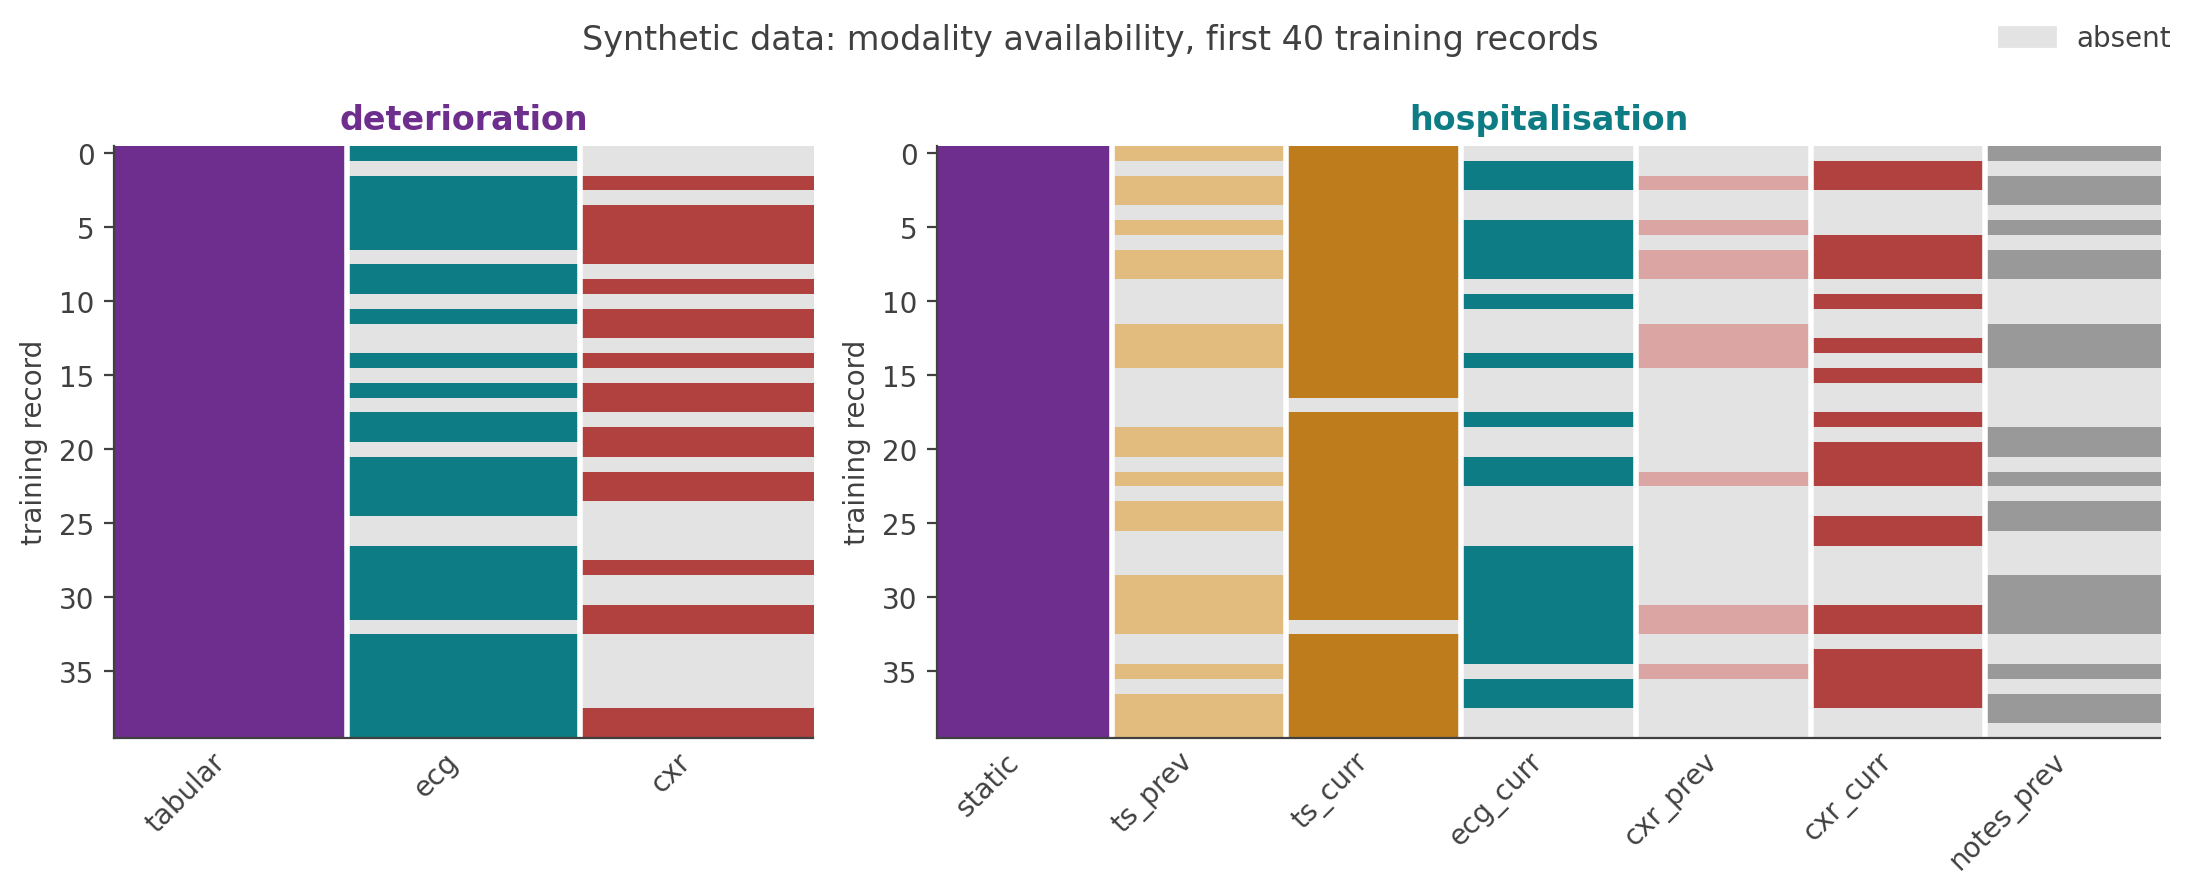

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [4, 7]})
for ax, task in zip(axes, TASKS):
    frame = frames[task]["train"].head(40)
    modalities = manifests[task]["modalities"]
    available = np.column_stack(
        [
            np.ones(len(frame), dtype=bool)
            if modality in TABULAR_MODALITIES
            else has(frame, modality).to_numpy()
            for modality in modalities
        ]
    )
    present_colours = np.array([to_rgb(MODALITY_COLOURS[modality]) for modality in modalities])
    image = np.where(available[..., None], present_colours[None, :, :], np.array(to_rgb(GRID)))
    ax.imshow(image, aspect="auto", interpolation="none")
    # White gaps between modality columns
    for boundary in np.arange(0.5, len(modalities) - 1):
        ax.axvline(boundary, color="white", linewidth=2)
    ax.set_xticks(range(len(modalities)), modalities, rotation=45, ha="right")
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel("training record")
    ax.set_title(task, color=TASK_COLOURS[task], fontweight="bold")
fig.legend(handles=[Patch(color=GRID, label="absent")], loc="upper right")
fig.suptitle("Synthetic data: modality availability, first 40 training records")
fig.tight_layout()
plt.show()

Inside a recorded modality, each measurement's block of nine summaries is observed in full,
missing in full when the measurement was never taken, or, in hospitalisation, missing only its
trend statistics after a single reading. The bars show the share of each outcome per measurement,
for the deterioration summaries in `tab_feats` and for the hospitalisation `ts_curr` summaries of
records that have them. Lab-like measurements are taken less often than vital-sign-like ones.

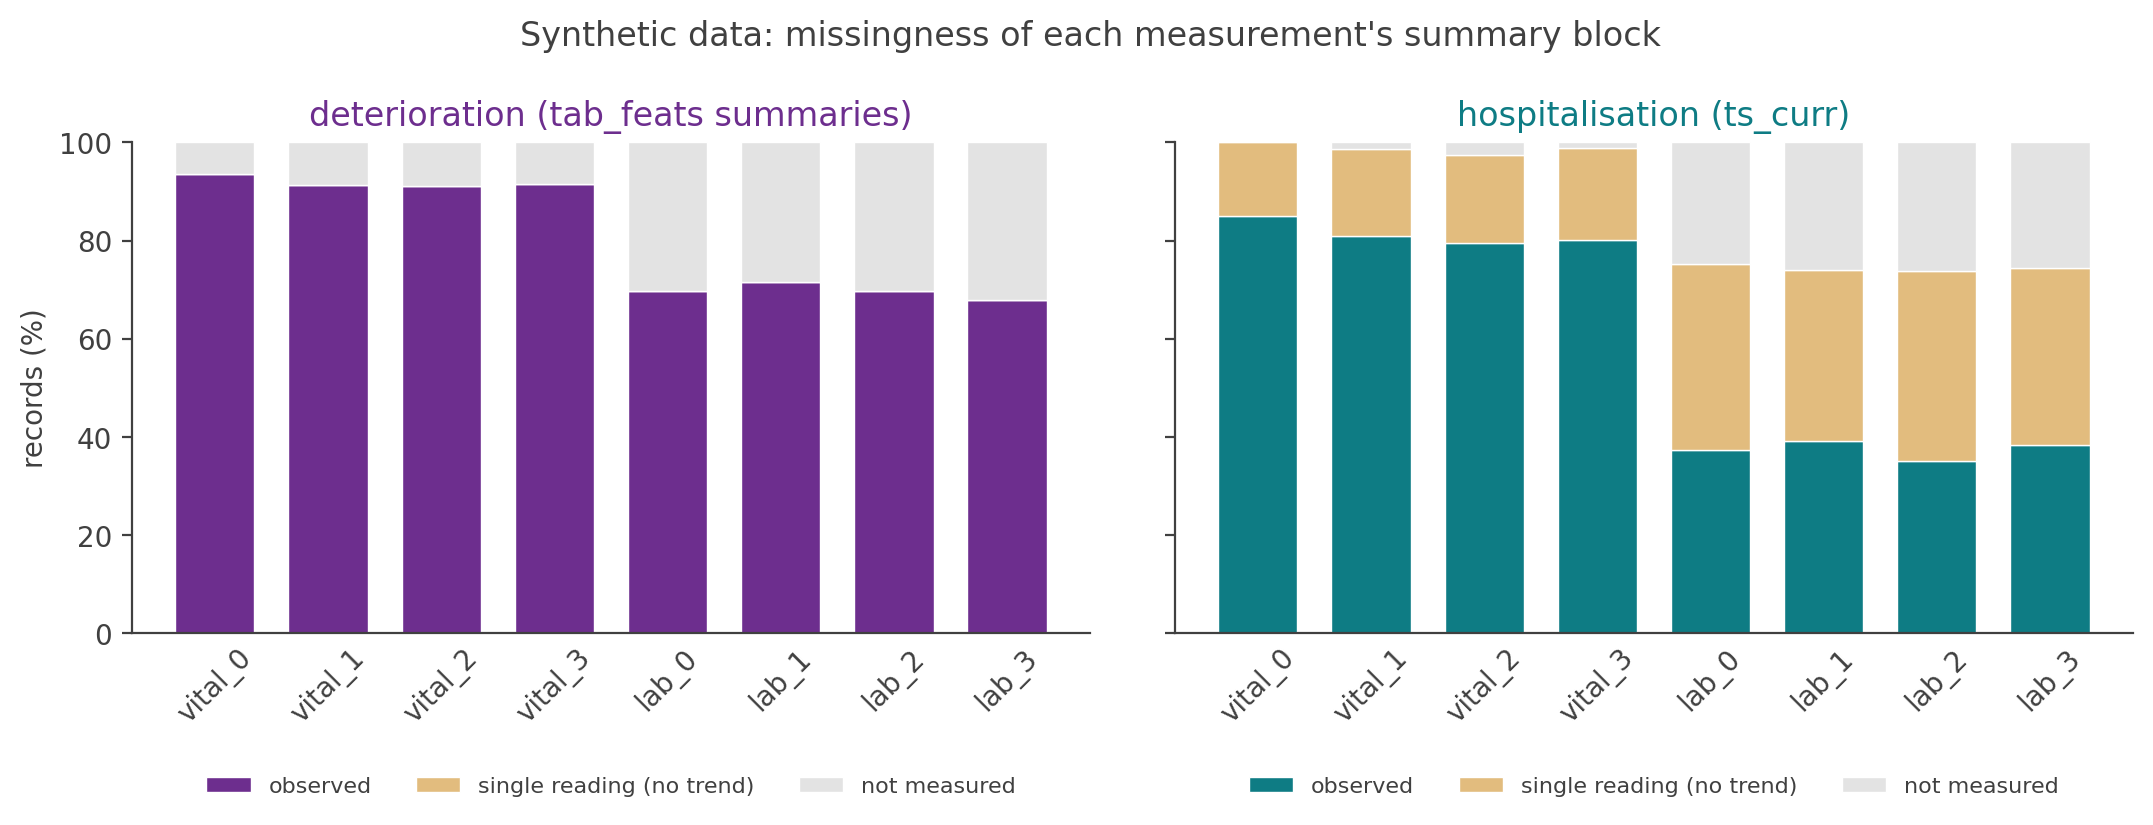

In [16]:
def block_status(masks: np.ndarray) -> pd.DataFrame:
    """Share of records per measurement whose summary block is observed, partly or fully missing."""
    missing_per_block = masks.reshape(len(masks), -1, n_stats).sum(axis=2)
    return pd.DataFrame(
        {
            "observed": (missing_per_block == 0).mean(axis=0),
            "single reading (no trend)": ((missing_per_block > 0) & (missing_per_block < n_stats)).mean(axis=0),
            "not measured": (missing_per_block == n_stats).mean(axis=0),
        }
    )


measurement_names = [name.removesuffix(f"_{SUMMARY_STATS[0]}") for name in ts_names[::n_stats]]
status = {
    "deterioration": block_status(np.stack(det["tab_missing"].to_list())[:, base_width:]),
    "hospitalisation": block_status(
        np.stack([mask[0] for mask in hosp["ts_curr_missing"] if len(mask) > 0])
    ),
}
status_colours = {"observed": None, "single reading (no trend)": "#E2BC7E", "not measured": GRID}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (task, table) in zip(axes, status.items()):
    bottom = np.zeros(len(table))
    for column, colour in status_colours.items():
        ax.bar(measurement_names, 100 * table[column], bottom=bottom, width=0.7,
               color=colour or TASK_COLOURS[task], edgecolor="white", linewidth=0.5, label=column)
        bottom += 100 * table[column].to_numpy()
    ax.set_title(
        f"{task} ({'tab_feats summaries' if task == 'deterioration' else 'ts_curr'})",
        color=TASK_COLOURS[task],
    )
    ax.tick_params(axis="x", rotation=45, length=0)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, fontsize=8)
axes[0].set_ylabel("records (%)")
fig.suptitle("Synthetic data: missingness of each measurement's summary block")
fig.tight_layout()
plt.show()

Both outcome classes appear in every split, at a similar rate.

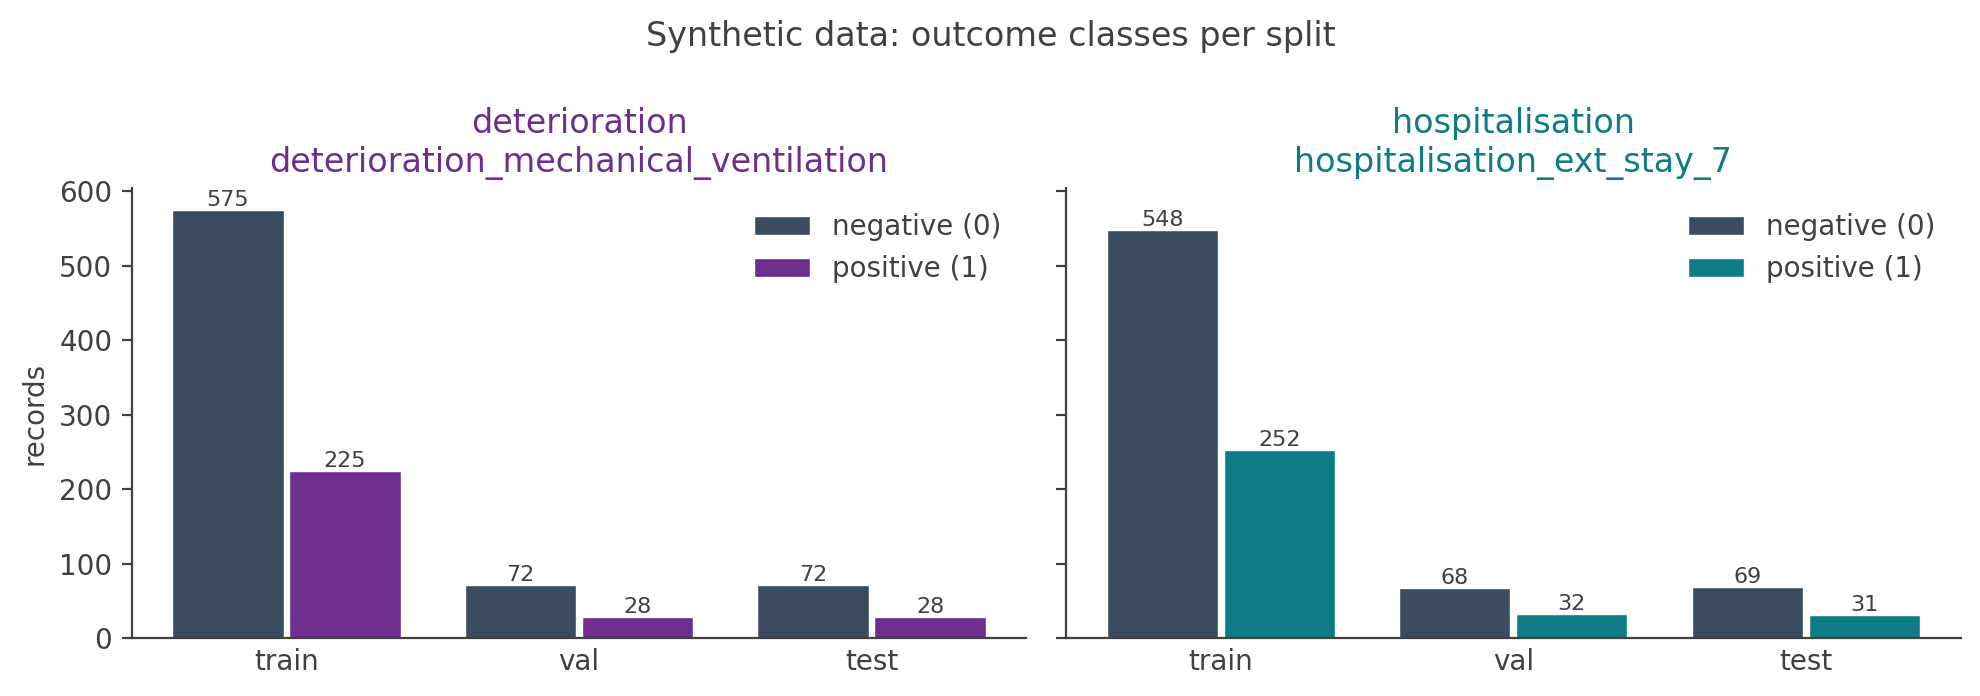

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
positions = np.arange(len(SPLIT_NAMES))
for ax, task in zip(axes, TASKS):
    outcome = OUTCOMES[task]
    negatives = [int((frames[task][split][outcome] == 0).sum()) for split in SPLIT_NAMES]
    positives = [int((frames[task][split][outcome] == 1).sum()) for split in SPLIT_NAMES]
    ax.bar(positions - 0.2, negatives, width=0.38, color=SLATE, edgecolor="white", linewidth=0.5,
           label="negative (0)")
    ax.bar(positions + 0.2, positives, width=0.38, color=TASK_COLOURS[task], edgecolor="white",
           linewidth=0.5, label="positive (1)")
    for position, negative, positive in zip(positions, negatives, positives):
        ax.text(position - 0.2, negative, negative, ha="center", va="bottom", fontsize=8)
        ax.text(position + 0.2, positive, positive, ha="center", va="bottom", fontsize=8)
    ax.set_xticks(positions, SPLIT_NAMES)
    ax.tick_params(axis="x", length=0)
    ax.set_title(f"{task}\n{outcome}", color=TASK_COLOURS[task])
    ax.legend(loc="upper right")
axes[0].set_ylabel("records")
fig.suptitle("Synthetic data: outcome classes per split")
fig.tight_layout()
plt.show()

### Demographics and planted bias

Each pathway folder also holds `synthetic_demographics.csv`, fictional demographics in the format of
the real cohort tables, for the fairness script's `--static` option. They are not model inputs.
The generator plants known biases in them, described in the manifest's `demographic_bias` entry.

In [18]:
display(pd.read_csv(OUTPUT_DIR / "hospitalisation" / DEMOGRAPHICS_FILENAME).head(3))
for attribute, description in manifests["hospitalisation"]["demographic_bias"].items():
    print(f"{attribute}: {description}\n")

,last_hadm_id,subject_id,demographics_gender,demographics_age,demographics_ethnicity,demographics_insurance
0,6000001,5000001,1,41,White,Private
1,6000002,5000002,0,65,White,Medicare
2,6000003,5000003,1,67,White,Medicare


sex: None. Sex is drawn independently of every factor, so it serves as a null control and fairness ratios should differ from 1 only by sampling noise.


age: Base-rate gap. Age rises with frailty and frailty raises outcome risk, so older age groups have a higher prevalence. Selection rates differ by age even for a well-calibrated model, which lowers the demographic parity ratio.


ethnicity: Information gap. Patients with unrecorded ethnicity (reported as Other by the fairness script) lose optional modalities and base features 0.35 more often, and their whole record, including which values are missing, follows acuity and frailty measured with extra error (standard deviation 1.0). Their outcome still follows the true factors, so their risk is unchanged. Models see less reliable signal for this group, so its discrimination is expected to be weaker, its error rates higher and the equalised odds and equal opportunity ratios lower.


insurance: Inherited base-rate gap (hospitalisation only). Medicare covers most patients aged 65 or over, so it inherits the higher prevalence of older groups. Insurance has no direct effect.


The table shows how the biases appear across all records of each pathway. Outcome prevalence
rises with age and follows it into Medicare. Patients with unrecorded ethnicity have fewer optional
modalities at an unchanged prevalence, and their features also measure risk with extra error,
which the table cannot show but which weakens a model's discrimination for this group. Sex shows
no planted gap.

In [19]:
group_rows = [
    {
        "pathway": task,
        "attribute": attribute,
        "group": group,
        "records": values["count"],
        "outcome prevalence (%)": round(100 * values["outcome_prevalence"], 1),
        "optional modalities present (%)": round(100 * values["optional_modality_availability"], 1),
    }
    for task, manifest in manifests.items()
    for attribute, groups in manifest["demographic_groups"].items()
    for group, values in groups.items()
]
display(pd.DataFrame(group_rows).set_index(["pathway", "attribute", "group"]))

records  outcome prevalence (%)  \
pathway         attribute group                                              
deterioration   sex       Female               492                    27.0   
                          Male                 508                    29.1   
                age       <30                   28                    17.9   
                          30-49                211                    19.9   
                          50-64                360                    24.7   
                          65-79                264                    35.6   
                          80+                  137                    37.2   
                ethnicity White                592                    28.4   
                          Black                161                    26.7   
                          Hispanic/Latino       65                    35.4   
                          Asian                 66                    25.8   
                          Unrecorded           116                    25.9   
hospitalisation sex       Female               492                    30.1   
                          Male                 508                    32.9   
                age       <30                   20                     5.0   
                          30-49                215                    13.5   
                          50-64                290                    27.2   
                          65-79                315                    36.8   
                          80+                  160                    56.2   
                ethnicity White                599                    29.5   
                          Black                157                    38.2   
                          Hispanic/Latino       80                    35.0   
                          Asian                 64                    31.2   
                          Unrecorded           100                    30.0   
                insurance Medicaid             203                    17.2   
                          Medicare             419                    43.2   
                          Other                 43                    27.9   
                          Private              335                    26.0   

                                           optional modalities present (%)  
pathway         attribute group                                             
deterioration   sex       Female                                      58.2  
                          Male                                        60.4  
                age       <30                                         58.9  
                          30-49                                       57.4  
                          50-64                                       60.3  
                          65-79                                       59.3  
                          80+                                         60.2  
                ethnicity White                                       62.7  
                          Black                                       61.8  
                          Hispanic/Latino                             64.6  
                          Asian                                       59.9  
                          Unrecorded                                  35.3  
hospitalisation sex       Female                                      56.9  
                          Male                                        58.4  
                age       <30                                         47.5  
                          30-49                                       55.6  
                          50-64                                       56.6  
                          65-79                                       59.1  
                          80+                                         60.9  
                ethnicity White                                       58.8  
        

## 6. PyTorch dataset loading

The existing dataset classes read the files unchanged. `DeteriorationDataset` reads `tabular`, `ecg`
and `cxr`. `HospitalisationDataset` reads the seven hospitalisation modalities and keys each sample
by `hadm_id`.

In [20]:
def tensor_table(sample: dict) -> pd.DataFrame:
    """List each tensor in a sample or batch with its shape and data type."""
    return pd.DataFrame(
        [
            {"name": name, "shape": tuple(value.shape), "dtype": str(value.dtype).replace("torch.", "")}
            for name, value in sample.items()
            if isinstance(value, torch.Tensor)
        ]
    )


det_dataset = DeteriorationDataset(resolve_split_path(OUTPUT_DIR / "deterioration", "train"))
print(f"{len(det_dataset)} samples, outcome {det_dataset.outcome}")
print(f"modalities {det_dataset.modality_names}, widths {det_dataset.feature_dims}")
sample = det_dataset[int(no_imaging.index[0])]
print(f"ed_stay_id {sample['ed_stay_id']}, label {sample['label']}")
print(f"ecg_missing {sample['ecg_missing']}, cxr_missing {sample['cxr_missing']}")
display(tensor_table(sample))

800 samples, outcome deterioration_mechanical_ventilation

modalities ('tabular', 'ecg', 'cxr'), widths {'tabular': 88, 'ecg': 768, 'cxr': 1024}

ed_stay_id 3000001, label 0.0

ecg_missing 0, cxr_missing 1

,name,shape,dtype
0,label,(),float32
1,tab_feats,"(88,)",float32
2,tab_missing,"(88,)",int64
3,ecg_feats,"(1, 768)",float32
4,ecg_time,"(0,)",float32
5,ecg_missing,(),int64
6,cxr_feats,"(0, 1024)",float32
7,cxr_time,"(0,)",float32
8,cxr_missing,(),int64


In [21]:
hosp_dataset = HospitalisationDataset(resolve_split_path(OUTPUT_DIR / "hospitalisation", "train"))
print(f"{len(hosp_dataset)} samples, outcome {hosp_dataset.outcome}")
sample = hosp_dataset[int(no_previous.index[0])]
print(f"hadm_id {sample['hadm_id']}, ed_stay_id {sample['ed_stay_id']}, label {sample['label']}")
display(tensor_table(sample))

800 samples, outcome hospitalisation_ext_stay_7

hadm_id 6000004, ed_stay_id 7000004, label 0.0

,name,shape,dtype
0,label,(),float32
1,tab_feats,"(16,)",float32
2,tab_missing,"(16,)",int64
3,ts_prev_feats,"(0, 72)",float32
4,ts_prev_time,"(0,)",float32
5,ts_prev_missing,"(0, 72)",int64
6,ts_curr_feats,"(1, 72)",float32
7,ts_curr_time,"(0,)",float32
8,ts_curr_missing,"(1, 72)",int64
9,ecg_curr_feats,"(1, 768)",float32


Each parquet cell becomes a tensor. An absent modality becomes an empty `[0, F]` tensor rather than
being dropped, so every sample has the same keys.

`get_dataloaders()` builds the same datasets from the `data` section of a training config, as
`src.train` does in section 8. `split_dir` points at the folder holding the three split files.

In [22]:
cfg = {
    "data": {
        "split_dir": str(OUTPUT_DIR / "deterioration"),
        "batch_size": 32,
        "collate_style": "fusemoe",
        "seed": 42,
    }
}
loaders = get_dataloaders(cfg)
for split, loader in loaders.items():
    print(f"{split}: {len(loader.dataset)} samples in {len(loader)} batches")

train: 800 samples in 25 batches

val: 100 samples in 4 batches

test: 100 samples in 4 batches

## 7. Training batch formats

A collate function turns a list of samples into one batch. Tabular vectors are stacked into
`[B, F]`. Each other modality becomes `[B, 1, F]`, zero where absent, with a `*_lengths` tensor that
is 1 where the modality is present and 0 where it is absent. The `concat`, `m3care` and `fusemoe`
collate styles share this contract. The static MoE model uses `fusemoe`.

In [23]:
samples = [det_dataset[index] for index in range(6)]
batch = get_collate_fn("fusemoe")(samples)
display(tensor_table(batch))
print(f"ecg_lengths {batch['ecg_lengths'].tolist()}, cxr_lengths {batch['cxr_lengths'].tolist()}")

,name,shape,dtype
0,ed_stay_id,"(6,)",int64
1,label,"(6,)",float32
2,tab_feats,"(6, 88)",float32
3,tab_missing,"(6, 88)",int64
4,ecg_feats,"(6, 1, 768)",float32
5,ecg_time,"(6, 0)",float32
6,ecg_lengths,"(6,)",int64
7,ecg_missing,"(6,)",int64
8,cxr_feats,"(6, 1, 1024)",float32
9,cxr_time,"(6, 0)",float32


ecg_lengths [1, 0, 1, 1, 1, 1], cxr_lengths [0, 0, 1, 0, 1, 1]

Padding never counts as data. Models read availability from the flags and lengths together, as
`batch_modality_availability()` does below.

In [24]:
availability = batch_modality_availability(batch)
display(pd.DataFrame({modality: mask.tolist() for modality, mask in availability.items()}))

,tabular,ecg,cxr
0,True,True,False
1,True,False,False
2,True,True,True
3,True,True,False
4,True,True,True
5,True,True,True


**Temporal models are not covered.** FuseMoE and mTAND-M3Care read observation times and the
deterioration `ts` time series, which only an all-record bundle provides. The next sections train the static MoE model on the deterioration files, evaluate it on the test
split and explain its predictions.

## 8. Model training

The static MoE model encodes each modality, routes every record to a few experts and combines their
predictions. `config/smp.yaml` uses a joint cosine router over seven experts, picks two per record
and adds a shared expert that sees every record. The cell below trains it on the deterioration files
with the config's own settings: up to 50 epochs, stopping once validation MCC has not improved for
10 epochs, and keeping the checkpoint with the best validation MCC.

Training runs `src.train` as from the command line, with two overrides: the synthetic split
folder, data loading in the notebook's own process, which MM-SHAP replaces in section 10. The run is written to `../logs/synthetic`. If it already exists, the cell
reuses it. Delete the run folder to train again.

In [25]:
LOG_DIR = DEFAULT_LOG_DIR / "synthetic"
TRAIN_CONFIG = REPO_ROOT / "config" / "smp.yaml"
RUN_ID = "notebook_demo"
det_dir = OUTPUT_DIR / "deterioration"

_, run_dir, _ = resolve_run_dir(
    {"split_dir": str(det_dir)}, OUTCOMES["deterioration"], "smp", RUN_ID,
    use_wandb=False, output_root=LOG_DIR,
)
checkpoint = run_dir / "checkpoint_best.ckpt"
if checkpoint.exists():
    print(f"Using the existing run in {shown(run_dir)}")
else:
    print(f"Training {TRAIN_CONFIG.name} into {shown(run_dir)}")
    command = [
        sys.executable, "-m", "src.train", "--config", str(TRAIN_CONFIG),
        "--run-id", RUN_ID, "--output-root", str(LOG_DIR),
        "--set", f"data.split_dir={det_dir}"
    ]
    result = subprocess.run(command, cwd=REPO_ROOT, capture_output=True, text=True, check=False)
    if result.returncode != 0:
        raise RuntimeError(f"Training failed:\n{result.stderr[-3000:]}")

history = pd.read_csv(run_dir / "history.csv")
best_epoch = int(history.loc[history["val_mcc"].idxmax(), "epoch"])
print(f"Trained {len(history)} epochs, best validation MCC at epoch {best_epoch}")

Using the existing run in ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo

Trained 15 epochs, best validation MCC at epoch 4

The run folder holds the config, the best checkpoint, `history.csv` with one row per epoch,
`metrics.csv` and the test predictions. The curves show the loss and MCC per epoch. The dashed line
marks the epoch of the saved checkpoint.

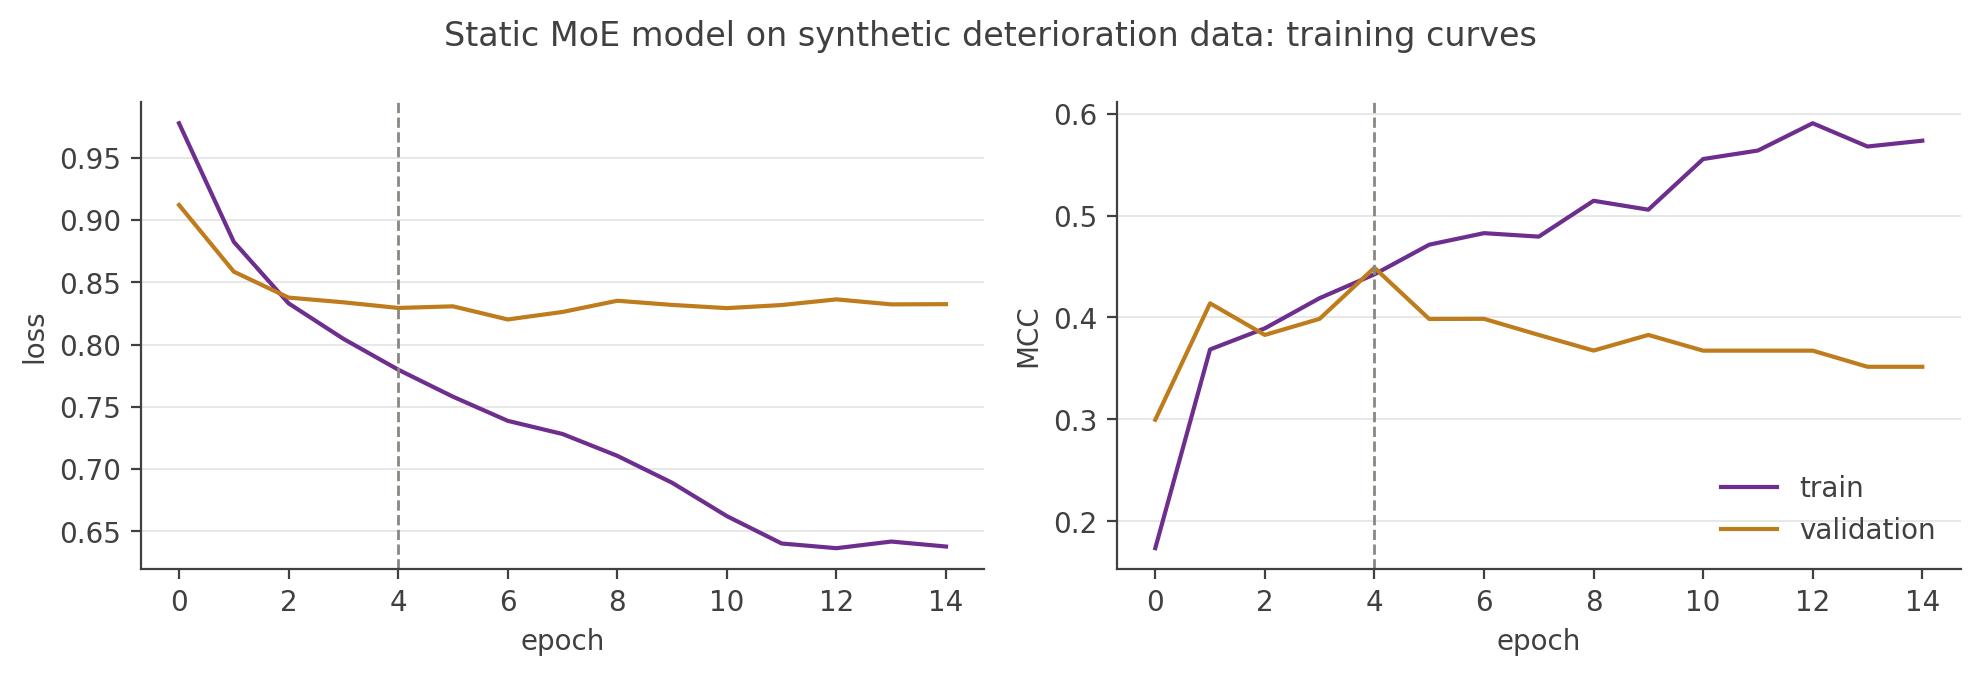

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, metric in zip(axes, ("loss", "mcc")):
    ax.plot(history["epoch"], history[f"train_{metric}"], color=PURPLE, label="train")
    ax.plot(history["epoch"], history[f"val_{metric}"], color=OCHRE, label="validation")
    ax.axvline(best_epoch, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xlabel("epoch")
    ax.set_ylabel(metric if metric == "loss" else "MCC")
    ax.grid(axis="y")
axes[1].legend(loc="lower right")
fig.suptitle("Static MoE model on synthetic deterioration data: training curves")
fig.tight_layout()
plt.show()

## 9. Model evaluation

After training, `src.train` reloads the best checkpoint and scores the test split. It writes one row
per test record to `test_predictions.csv`: the stay ID, the true label, the predicted probability
and the prediction at a threshold of 0.5.

In [27]:
predictions = read_predictions(run_dir / "test_predictions.csv")
display(predictions.head())

,ed_stay_id,label,probability,prediction
0,3000019,0,0.678067,1
1,3000027,0,0.378806,0
2,3000036,0,0.809967,1
3,3000046,0,0.241023,0
4,3000053,0,0.368872,0


`metrics.csv` holds the metrics of the best checkpoint on every split, computed with the same
metric classes as during training. The validation and test splits hold only 100 records each, so
their metrics are noisy.

In [28]:
METRIC_NAMES = {
    "auroc": "AUROC", "mcc": "MCC", "ba": "balanced accuracy",
    "recall": "recall", "specificity": "specificity",
}
metrics = pd.read_csv(run_dir / "metrics.csv").iloc[0]
display(
    pd.DataFrame(
        {split: {name: metrics[f"{split}_{key}"] for key, name in METRIC_NAMES.items()}
         for split in SPLIT_NAMES}
    ).round(3)
)

,train,val,test
AUROC,0.825,0.761,0.825
MCC,0.467,0.449,0.471
balanced accuracy,0.752,0.731,0.762
recall,0.742,0.643,0.857
specificity,0.762,0.819,0.667


## 10. Model interpretation

`explain_checkpoint()` is the function behind `python -m src.explanation.explain`. It computes
MM-SHAP modality contributions and tabular feature SHAP values for every test record and writes
them to the run's `explanation/` folder. It also draws a decision plot for each patient passed in
`stays`. The cell below asks for one test patient who has both an ECG and a CXR. The default
gradient explainer uses 100 training records as background. The cell hides the progress bars.

In [29]:
test_frame = frames["deterioration"]["test"]
example_stay = int(
    test_frame.loc[(test_frame["ecg_missing"] == 0) & (test_frame["cxr_missing"] == 0), "ed_stay_id"].iloc[0]
)
with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
    explanation = explain_checkpoint(checkpoint, stays=[example_stay])
plt.switch_backend(NOTEBOOK_BACKEND)
for name, path in explanation.items():
    print(f"{name}: {shown(path)}")

mm_shap_json: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/mm_shap_modality_contribution.json

shap_manifest_json: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/shap_manifest.json

mm_shap_csv: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/mm_shap_per_sample.csv

mm_shap_plot: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/mm_shap_modality_contribution.png

feature_importance_csv: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/shap_global_tabular_importance.csv

feature_summary_heatmap: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/shap_global_tabular_summary_heatmap.png

feature_local_stay3000019: ../logs/synthetic/deterioration/base/deterioration_mechanical_ventilation/runs/smp_notebook_demo/explanation/shap_global_tabular_decision_stay3000019.png

### Modality contribution

MM-SHAP gives each modality its share of a prediction, from how much the predicted probability
changes when the modality is removed, averaged over every combination of the other modalities. The
shares of one record add up to 1. A record without a CXR gives the CXR no share, so the saved plot
splits the test records by CXR availability, with bootstrap confidence intervals. In the generator,
every modality carries the shared illness severity and frailty, and the ECG and CXR also carry extra
outcome signal, so each modality is expected to contribute.

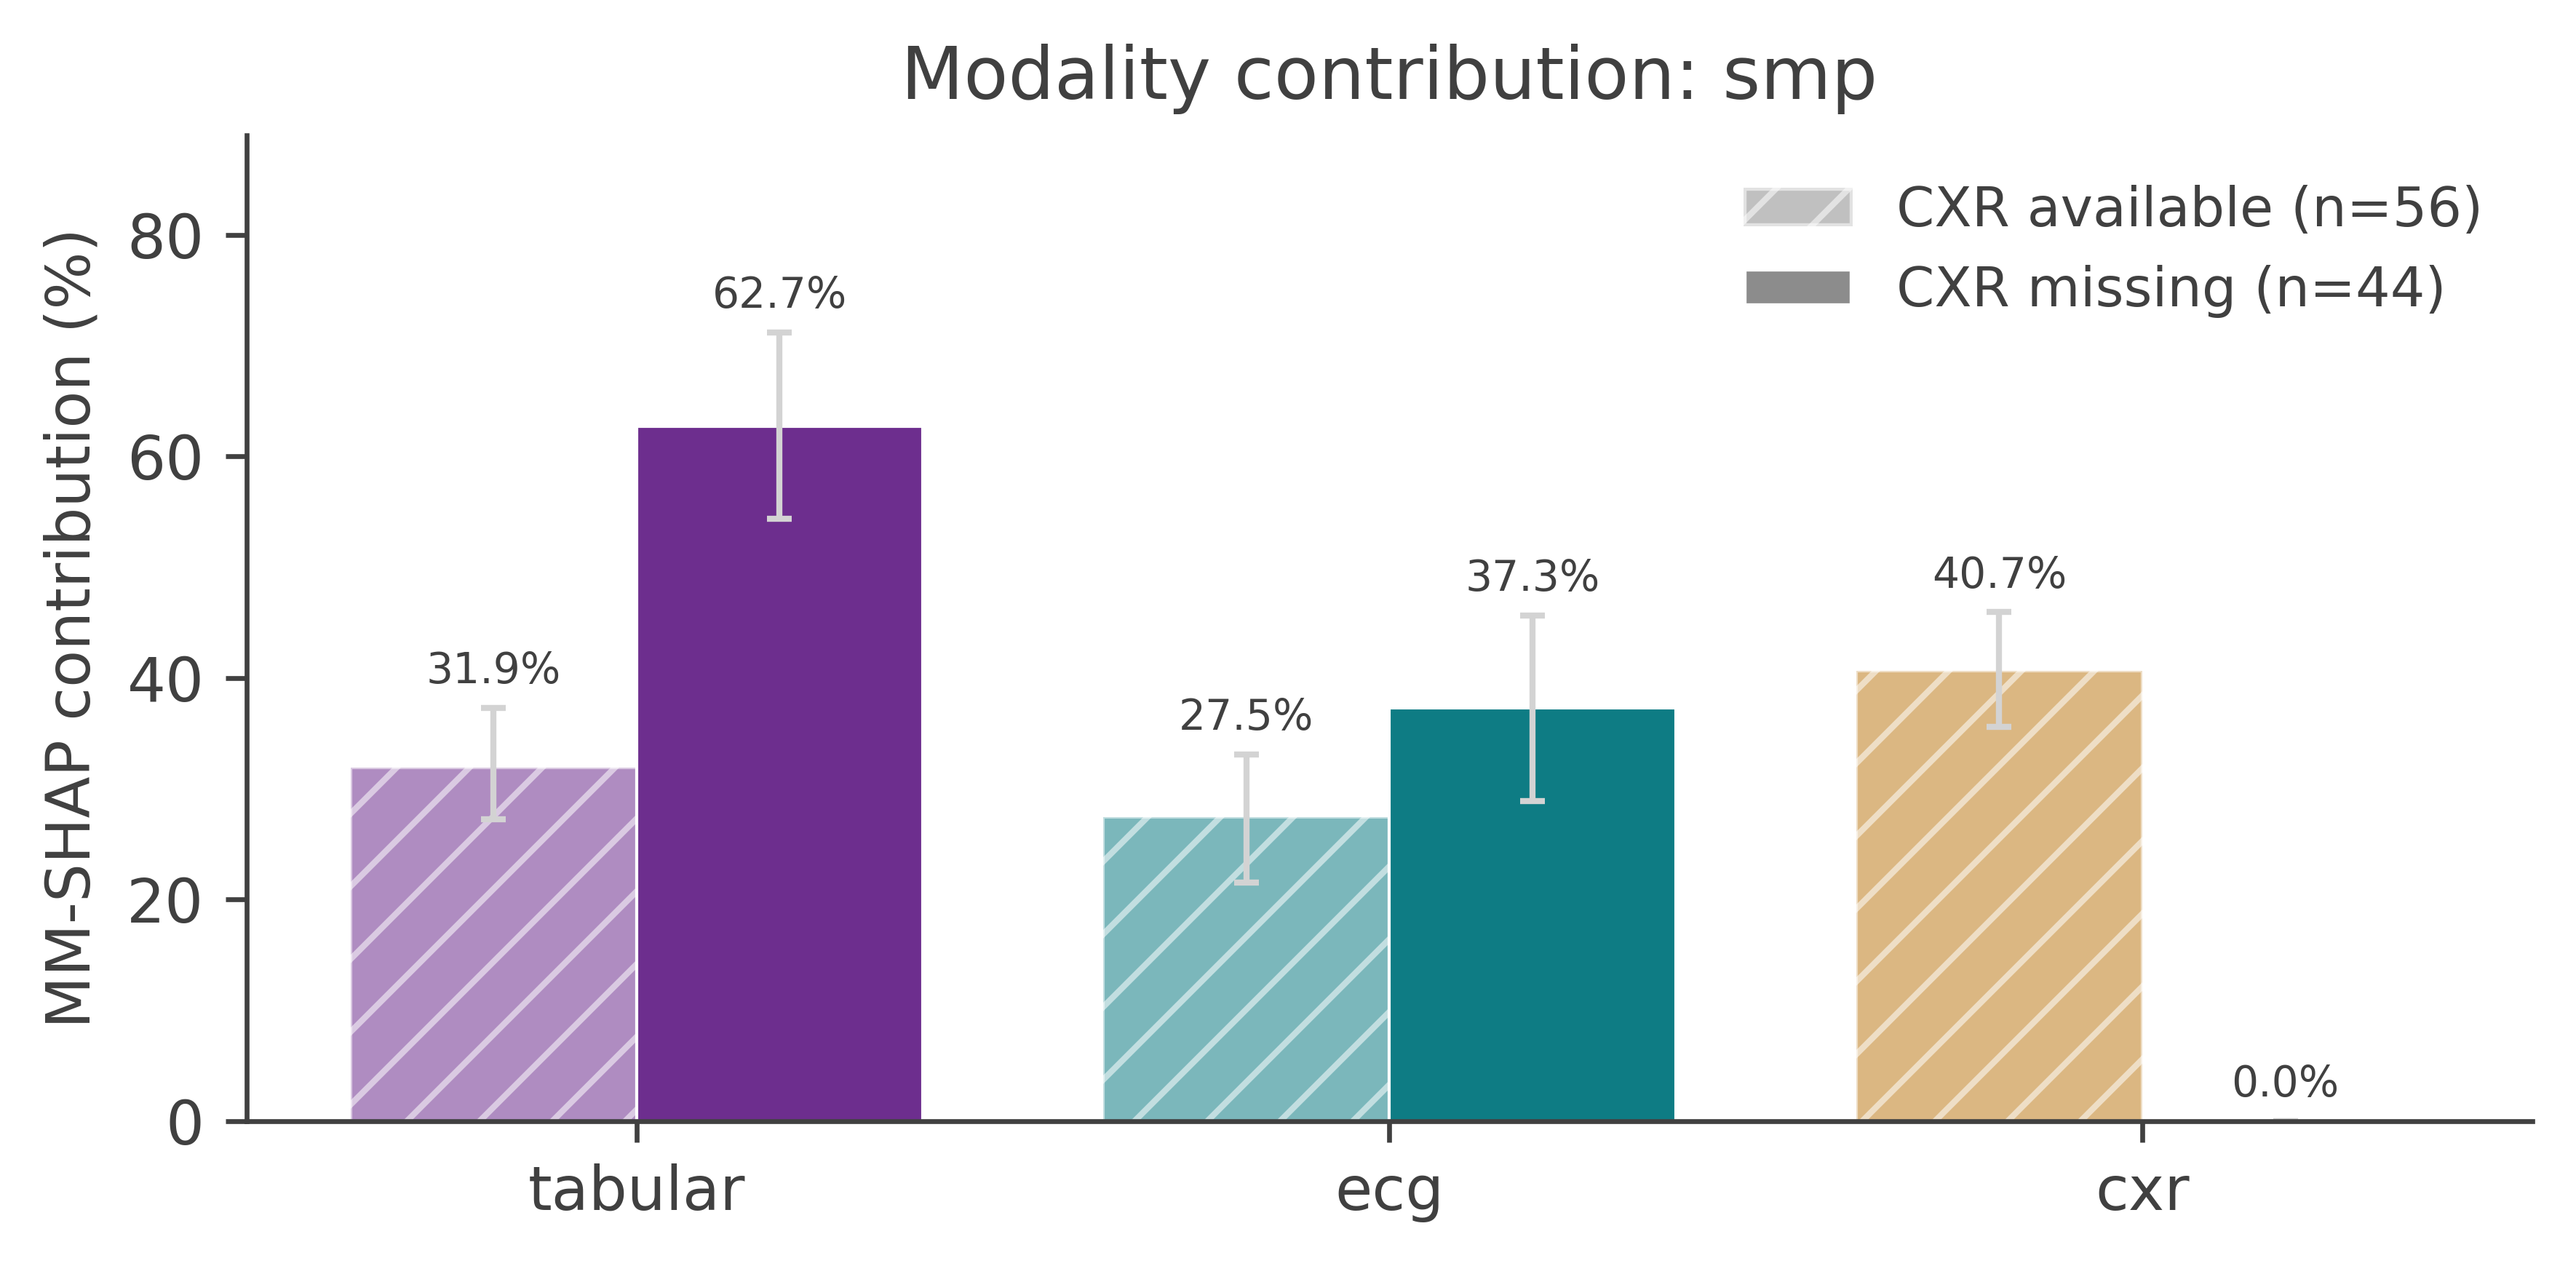

In [30]:
# The saved plot has a transparent background, so place it on white for display
mm_plot = PILImage.open(explanation["mm_shap_plot"]).convert("RGBA")
on_white = PILImage.new("RGBA", mm_plot.size, "white")
on_white.alpha_composite(mm_plot)
buffer = BytesIO()
on_white.convert("RGB").save(buffer, format="PNG")
display(Image(data=buffer.getvalue(), width=700))

### Feature explanation

Tabular feature SHAP values show which entries of the tabular vector move the predicted probability
the most. In the saved heatmap each column is one test record and each row a feature, coloured by
its SHAP value. The line above shows each record's predicted probability, and records with similar
explanations sit next to each other. The features are ranked by mean absolute SHAP value. Feature
names such as `base_11` or `lab_3_mean` are labels without clinical meaning.

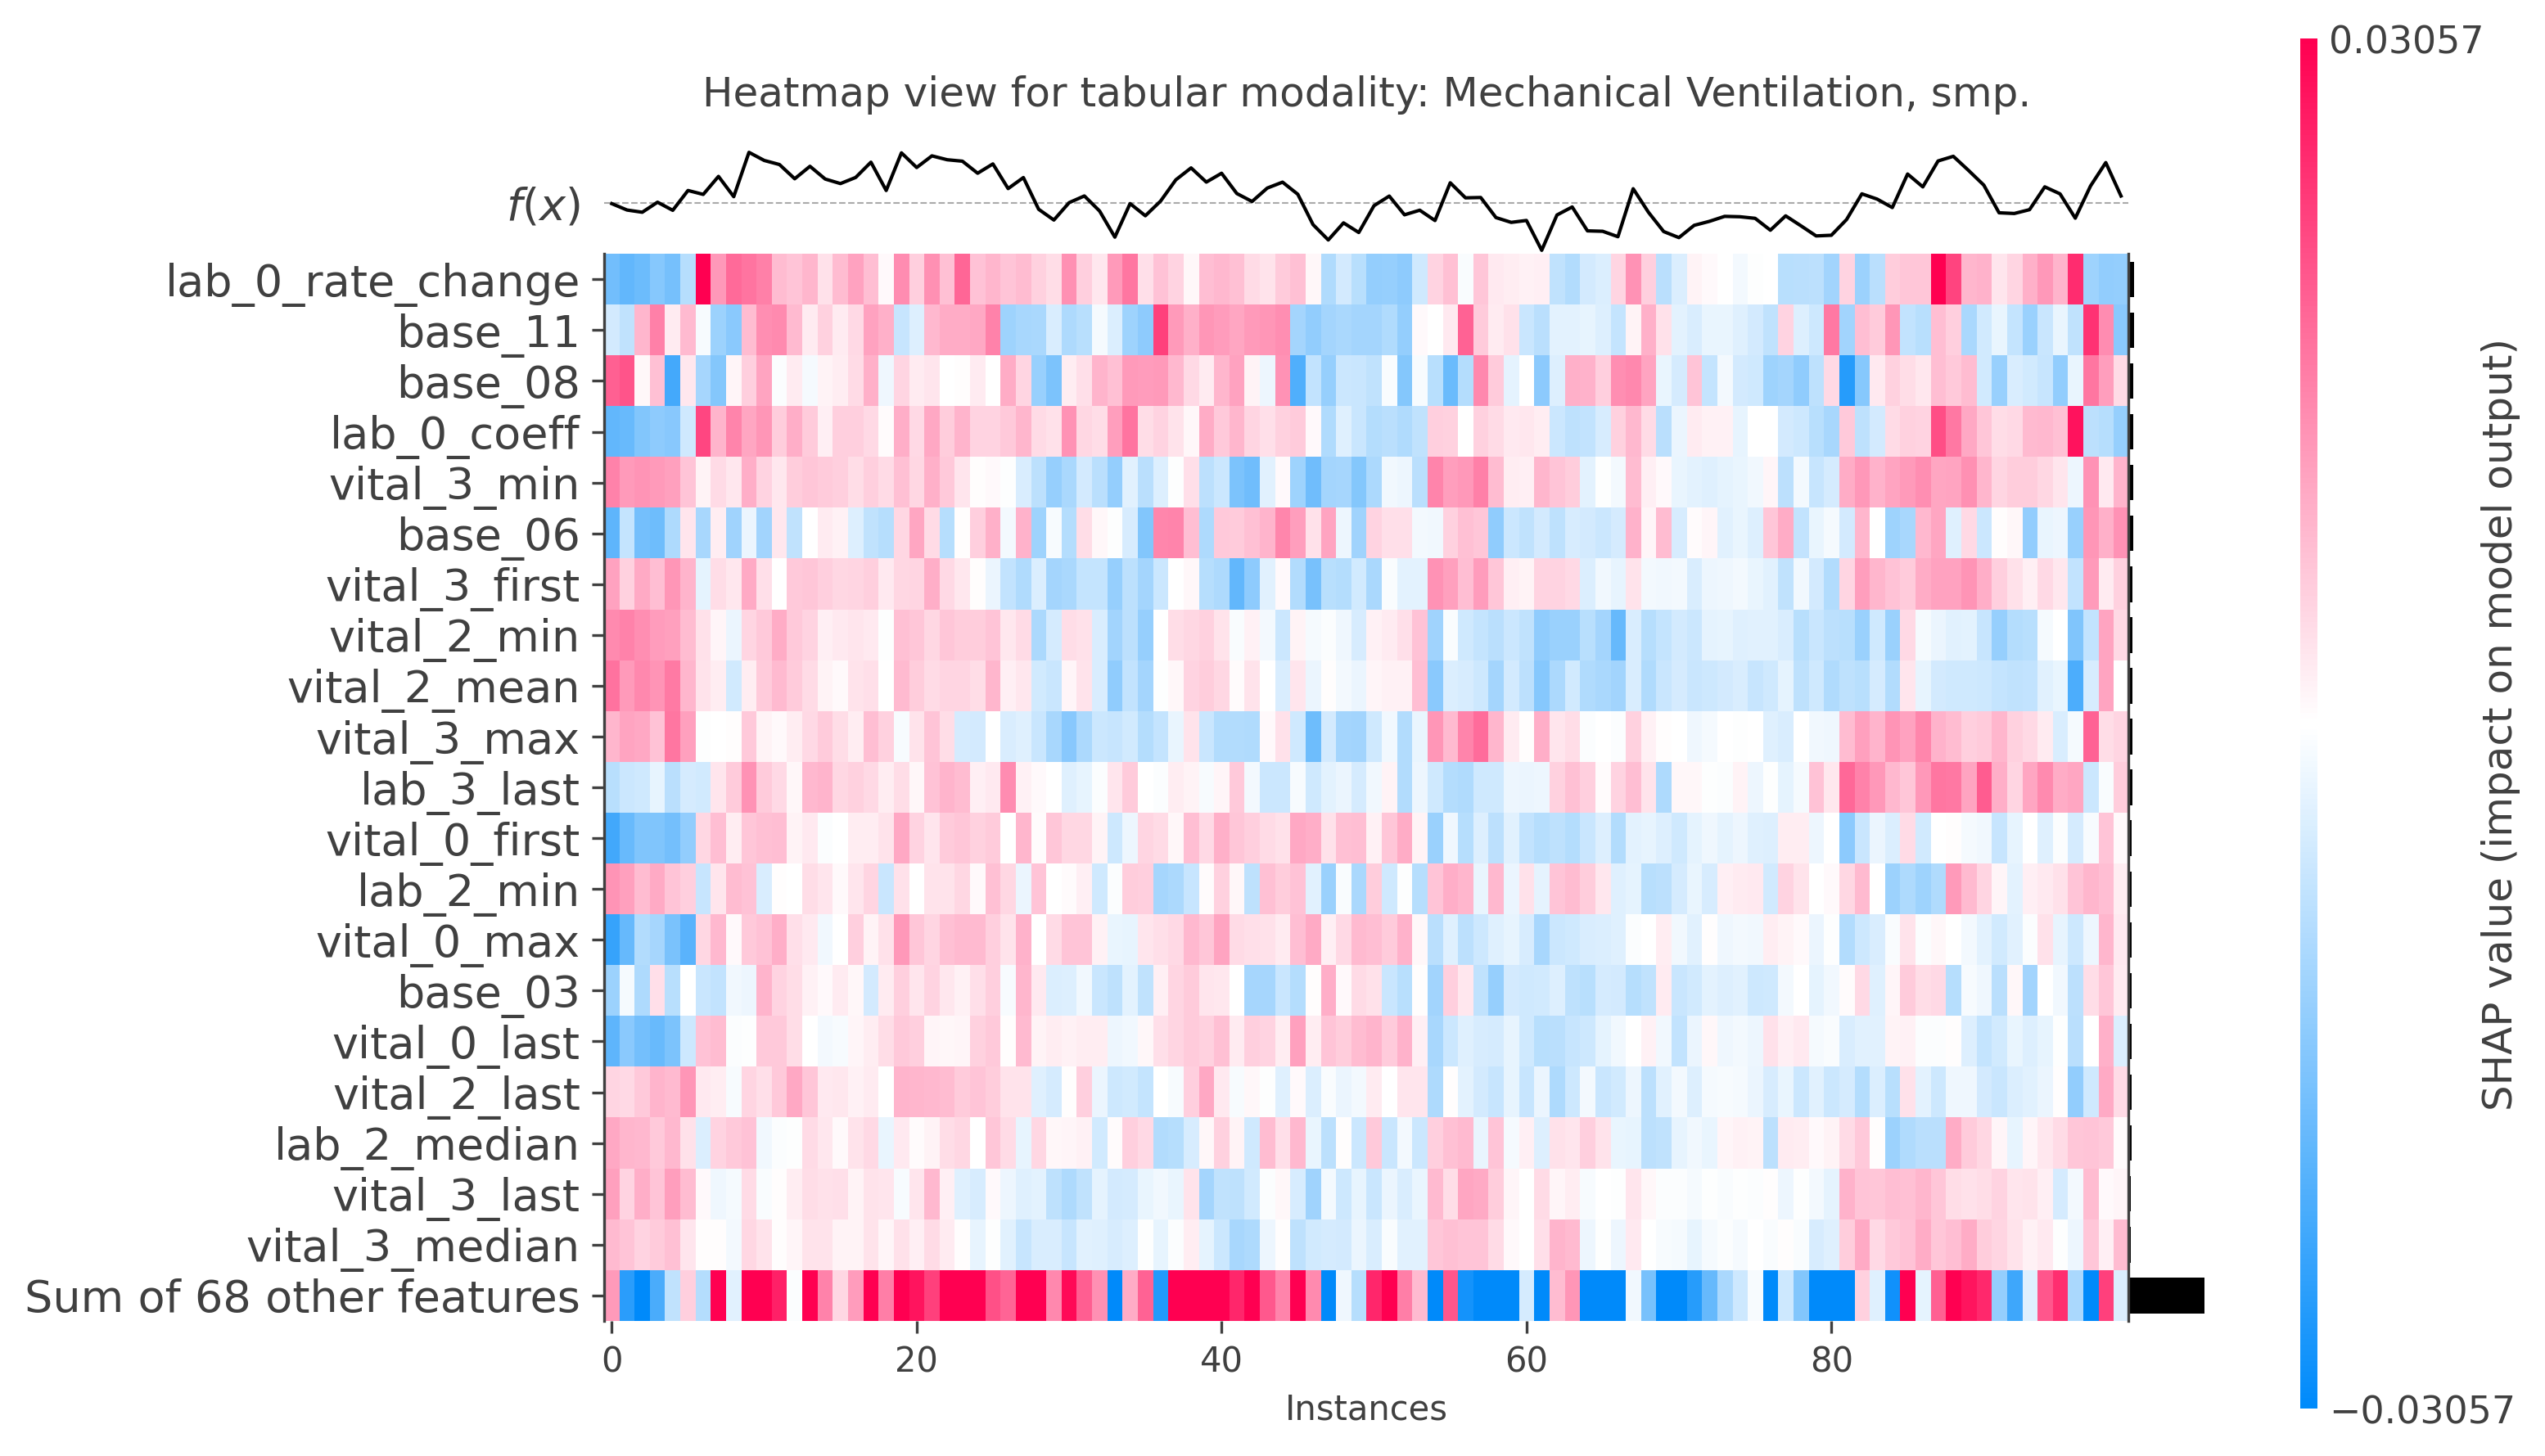

In [31]:
display(Image(filename=explanation["feature_summary_heatmap"], width=600))

### Patient decision plot

The decision plot explains the prediction for one patient. The grey vertical line is the reference
prediction, the average over the background training records. Read from the bottom up: the line
adds one tabular feature's SHAP value at each row and ends near the patient's predicted probability.
Gradient SHAP is an approximation, so the end point can differ slightly from the probability in the
title. Only the 15 most important features are drawn, and the rest shift the starting point at the
bottom. The brackets give the patient's feature values, and *imputed* marks values that were missing
and imputed. The title gives the true label, the predicted probability and the patient's modality
shares.

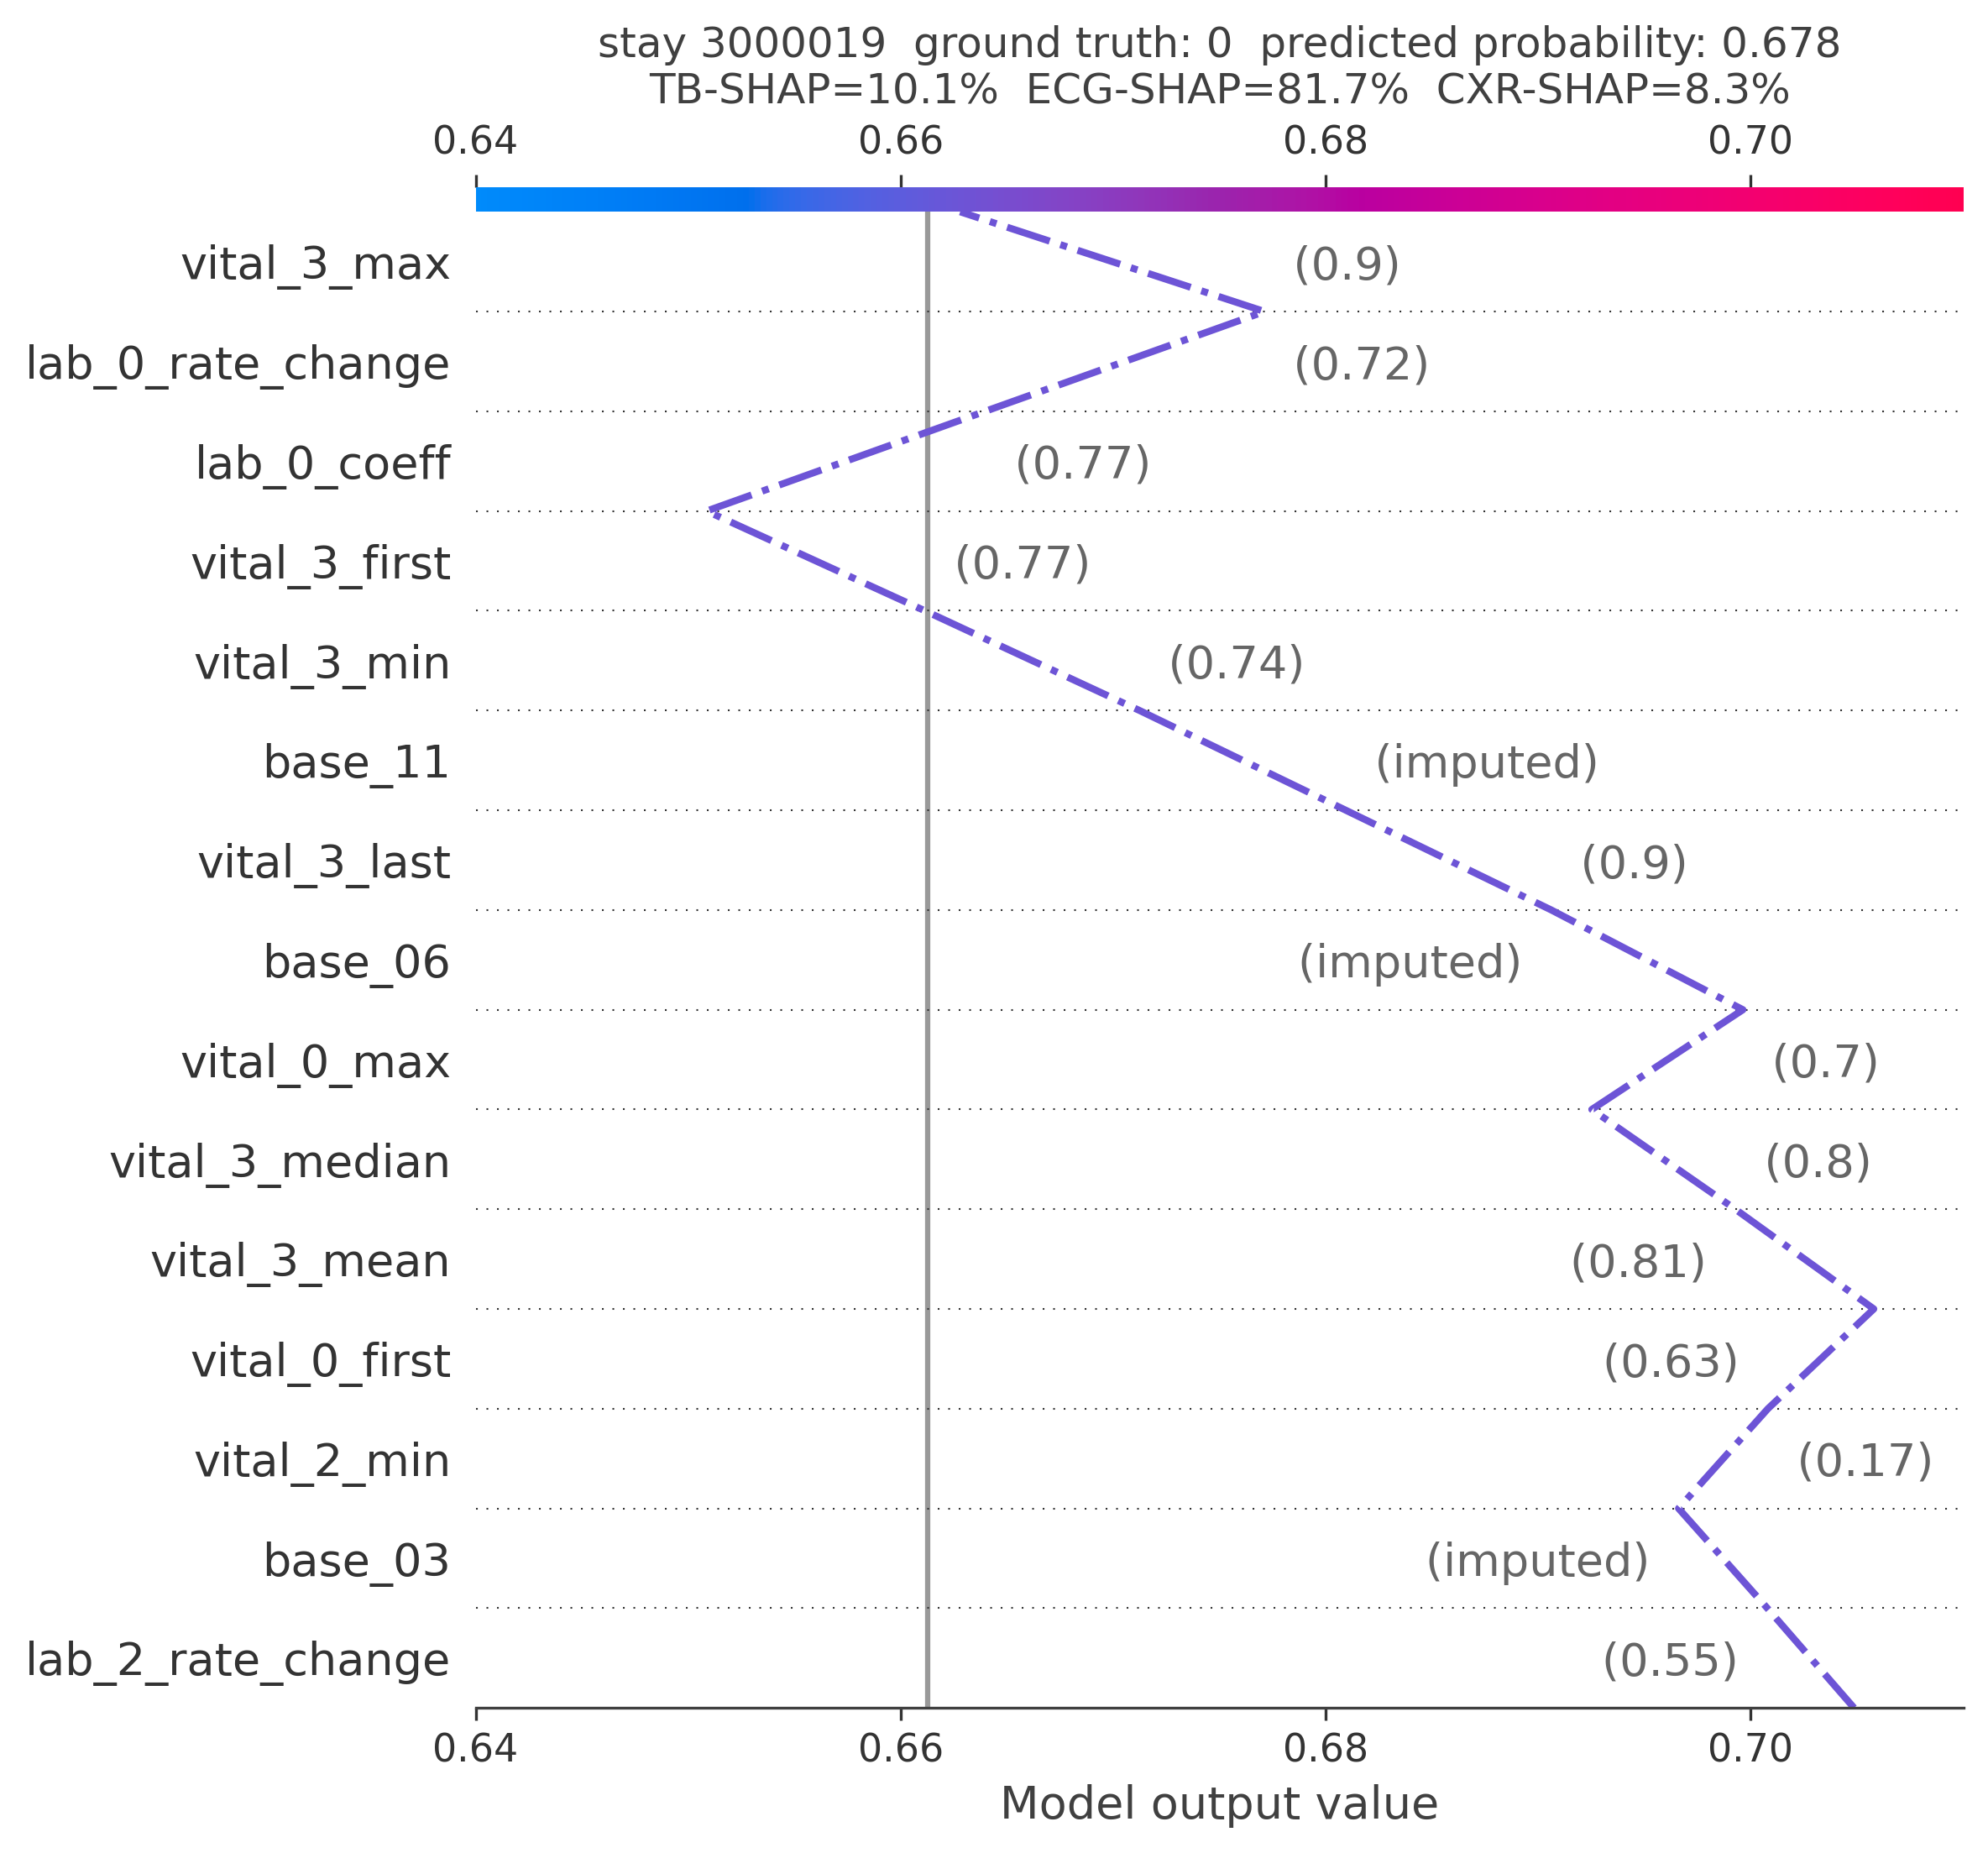

In [32]:
display(Image(filename=explanation[f"feature_local_stay{example_stay}"], width=600))

## 11. Fairness evaluation

`compute_fairness_for_run()` is the function behind `python -m src.evaluation.fairness`. It joins
the test predictions to `synthetic_demographics.csv` and compares groups by sex, age, ethnicity and
CXR availability. Each ratio divides the lowest group rate by the highest, so 1 means no gap.
Demographic parity compares selection rates, equalised odds the worse of the true and false positive
rate ratios, and equal opportunity the true positive rates. The brackets hold bootstrap confidence
intervals. Results go to the run's `fairness/` folder.

In [33]:
with redirect_stdout(StringIO()):
    fairness = compute_fairness_for_run(
        run_dir / "test_predictions.csv", run_dir / "config.yaml",
        det_dir / DEMOGRAPHICS_FILENAME, run_dir / "fairness", n_boot=200,
    )
plt.switch_backend(NOTEBOOK_BACKEND)
RATIO_NAMES = {"DPR": "demographic parity", "EQO": "equalised odds", "EOP": "equal opportunity"}
display(
    pd.DataFrame(
        {
            attribute: {
                name: f"{ratios[key]['value']:.3f} [{ratios[key]['ci_low']:.3f}, {ratios[key]['ci_high']:.3f}]"
                for key, name in RATIO_NAMES.items()
            }
            for attribute, ratios in fairness["attributes"].items()
        }
    ).T
)

,demographic parity,equalised odds,equal opportunity
Sex,"0.868 [0.605, 0.994]","0.692 [0.464, 0.883]","0.692 [0.393, 0.907]"
Age,"0.000 [0.000, 0.000]","0.001 [0.001, 0.001]","0.001 [0.001, 0.001]"
Ethnicity,"0.464 [0.265, 0.769]","0.001 [0.001, 0.001]","0.001 [0.001, 0.001]"
CXR Availability,"0.698 [0.407, 0.962]","0.671 [0.240, 0.912]","0.900 [0.631, 0.995]"


Compare the groups with the planted biases in section 5. Sex is a null control. Older patients are
frailer, which raises their outcome rate, so older groups are selected more often. Patients with unrecorded ethnicity, shown as
Other, have sparser and noisier records. A record without a CXR is more likely to be low acuity. The
bars show the selection rate and false negative rate of every group, with its size below.

With 100 test records many groups hold only a handful of patients. One small group can drive a ratio
to 0, and the odds ratios are floored at 0.001. Generate more records with `--n-samples` for clearer
estimates.

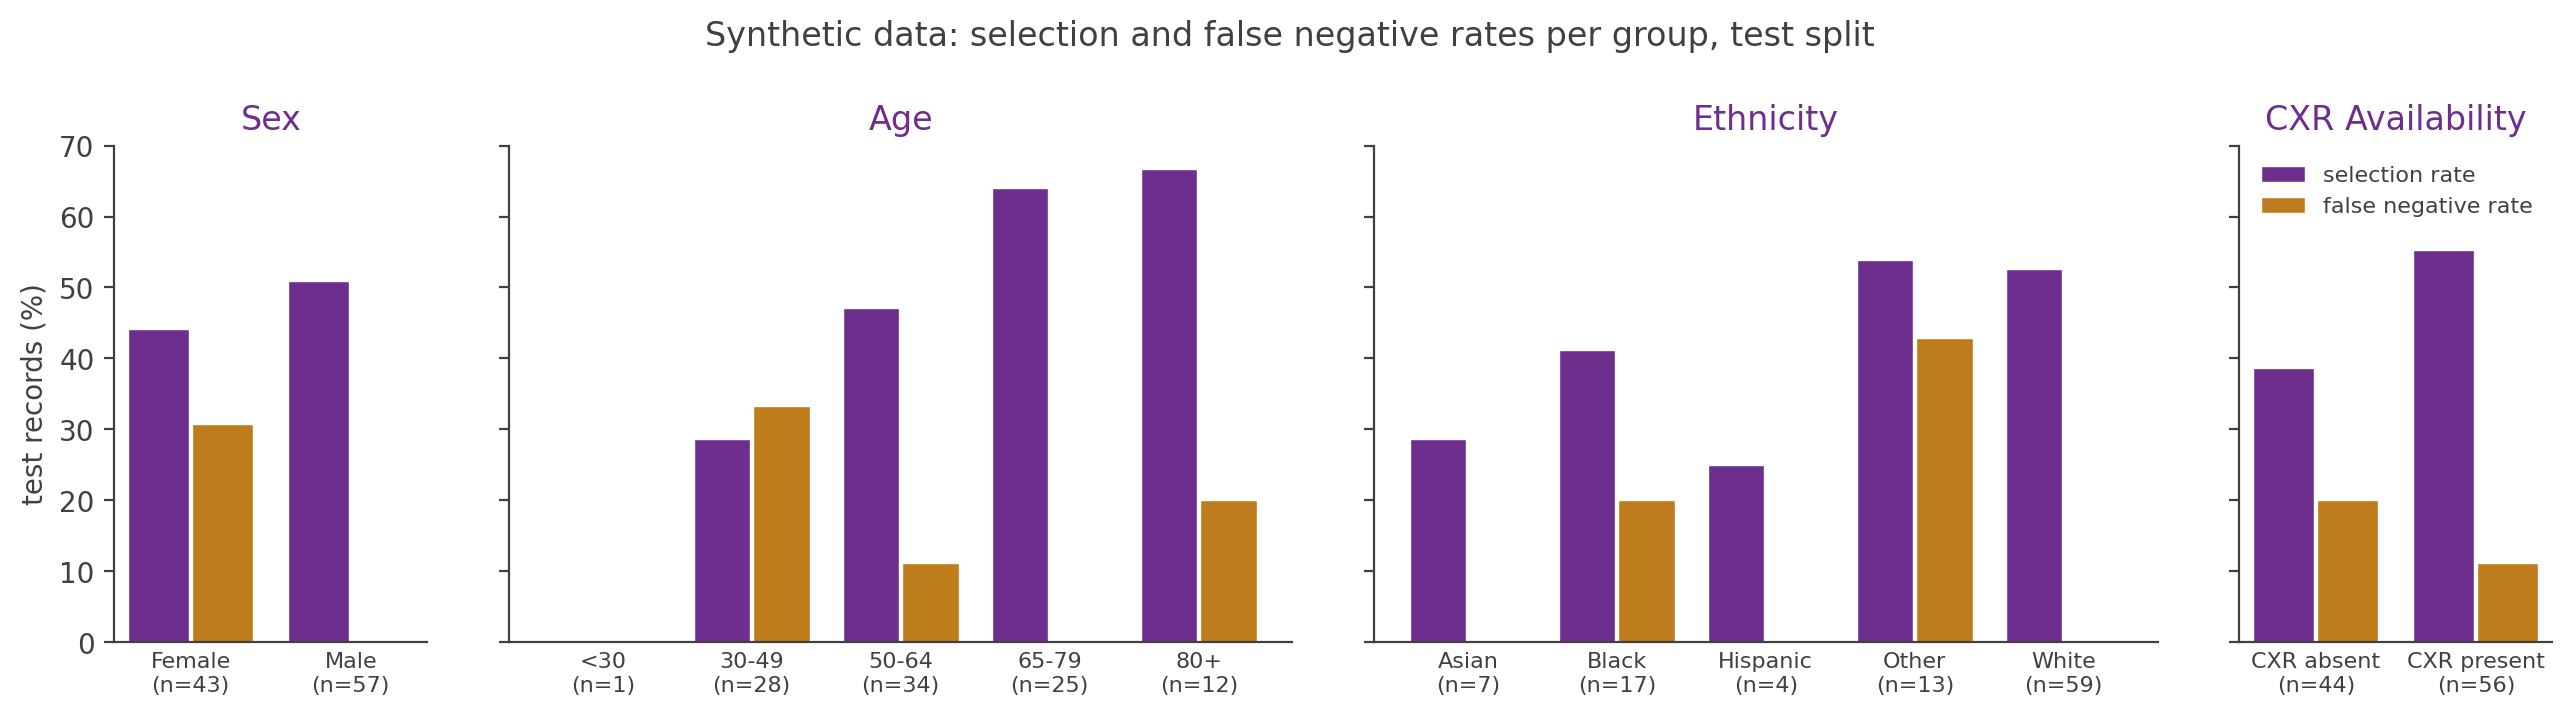

In [34]:
attributes = fairness["attributes"]
fig, axes = plt.subplots(
    1, len(attributes), figsize=(13, 3.6), sharey=True,
    gridspec_kw={"width_ratios": [len(values["groups"]) for values in attributes.values()]},
)
for ax, (attribute, values) in zip(axes, attributes.items()):
    groups = values["groups"]
    positions = np.arange(len(groups))
    ax.bar(positions - 0.2, [100 * group["selection_rate"] for group in groups.values()], width=0.38,
           color=PURPLE, edgecolor="white", linewidth=0.5, label="selection rate")
    ax.bar(positions + 0.2, [100 * group["fnr"] for group in groups.values()], width=0.38,
           color=OCHRE, edgecolor="white", linewidth=0.5, label="false negative rate")
    ax.set_xticks(positions, [f"{name}\n(n={group['count']})" for name, group in groups.items()],
                  fontsize=8)
    ax.tick_params(axis="x", length=0)
    ax.set_title(attribute, color=PURPLE)
axes[0].set_ylabel("test records (%)")
axes[-1].legend(loc="upper right", fontsize=8)
fig.suptitle("Synthetic data: selection and false negative rates per group, test split")
fig.tight_layout()
plt.show()